# ML_2. Линейные модели для регрессии

# 1. Ответы на вопросы

## 1.1. Аналитическое решение задачи регрессии

Обозначения: $X \in \mathbb{R}^{n \times d}$ - матрица "объекты × признаки", $y \in \mathbb{R}^{n}$ - вектор правильных ответов, $w \in \mathbb{R}^{d}$ - веса модели. Свободный член $b$ спрячем в веса: добавим к $X$ столбец из единиц, тогда прогноз модели - $\hat y = Xw$.

Минимизируем сумму квадратов ошибок (это MSE, умноженная на $n$; множитель не меняет точку минимума):

$$Q(w) = \|y - Xw\|^2 = (y - Xw)^\top (y - Xw) = y^\top y - 2\,w^\top X^\top y + w^\top X^\top X\, w .$$

Градиент по $w$ (правила $\nabla_w\, a^\top w = a$ и $\nabla_w\, w^\top A w = 2Aw$ для симметричной матрицы $A$):

$$\nabla_w Q = -2X^\top y + 2X^\top X\, w = 2X^\top (Xw - y).$$

Приравниваем градиент к нулю и получаем **нормальное уравнение**:

$$X^\top X\, w = X^\top y \quad\Longrightarrow\quad w^{*} = (X^\top X)^{-1} X^\top y .$$

- **Это минимум.** Матрица вторых производных $\nabla^2 Q = 2X^\top X$ неотрицательно определена: $v^\top X^\top X v = \|Xv\|^2 \ge 0$ для любого $v$. Значит, $Q$ выпукла, и точка с нулевым градиентом - глобальный минимум. Если столбцы $X$ линейно независимы, $X^\top X$ обратима и решение единственно.
- **Геометрия.** Нормальное уравнение можно записать как $X^\top (y - Xw^{*}) = 0$: вектор ошибок ортогонален всем столбцам $X$. То есть $\hat y = Xw^{*}$ - ортогональная проекция $y$ на пространство, натянутое на признаки.
- **Если $X^\top X$ вырождена** (признаков больше, чем объектов, или один признак - линейная комбинация других), решений бесконечно много. Тогда берут решение с наименьшей нормой $w^{*} = X^{+} y$, где $X^{+}$ - псевдообратная матрица, или добавляют регуляризацию (п. 1.2). Именно это случится с полиномиальными признаками в п. 8.
- **Вычисления.** Построить $X^\top X$ стоит $O(nd^2)$ операций, обратить - $O(d^3)$. На практике обратную матрицу явно не считают, а решают систему через разложения (Холецкого, QR, SVD), как `np.linalg.solve` и `np.linalg.lstsq`. При большом числе признаков или объектов выгоднее градиентный спуск: один шаг SGD стоит всего $O(d)$.

## 1.2. Что меняется в решении при L1- и L2-регуляризации

**L2 (Ridge).** $Q(w) = \|y - Xw\|^2 + \lambda \|w\|_2^2$. Градиент $2X^\top(Xw - y) + 2\lambda w$ приравниваем к нулю:

$$(X^\top X + \lambda I)\, w = X^\top y \quad\Longrightarrow\quad w^{*} = (X^\top X + \lambda I)^{-1} X^\top y .$$

- Решение по-прежнему записывается явно - к $X^\top X$ добавляется $\lambda I$. Все собственные числа матрицы $X^\top X + \lambda I$ не меньше $\lambda > 0$, поэтому она **всегда обратима**: решение единственно и устойчиво даже при коллинеарных признаках и при $d > n$.
- Веса **сжимаются к нулю**, но не обнуляются. Сингулярное разложение $X = U S V^\top$ показывает, как именно: каждая компонента решения МНК умножается на $s_i^2 / (s_i^2 + \lambda)$. Сильнее всего подавляются направления с маленькими сингулярными числами - шумные и коллинеарные.
- Свободный член не штрафуют (на его месте в $\lambda I$ стоит 0, либо данные центрируют), иначе прогноз зависел бы от сдвига цены.
- В градиентном спуске к градиенту добавляется $2\lambda w$, и шаг превращается в $w \leftarrow (1 - 2\eta\lambda)\, w - \eta\, \nabla \|y - Xw\|^2$: на каждом шаге веса немного уменьшаются - отсюда второе название, *weight decay*.
- С точки зрения вероятностей это MAP-оценка с нормальным априорным распределением весов $w \sim \mathcal{N}(0, \tau^2 I)$, где $\lambda = \sigma^2/\tau^2$ (теория в README).

**L1 (Lasso).** $Q(w) = \|y - Xw\|^2 + \lambda \|w\|_1$. Модуль не дифференцируем в нуле, поэтому:

- **Аналитического решения в общем случае нет.** Вместо градиента - субградиент: $\partial \lvert w_j \rvert = \operatorname{sign}(w_j)$ при $w_j \ne 0$ и любое число из отрезка $[-1, 1]$ при $w_j = 0$.
- Условия оптимальности: $2X_j^\top (y - Xw) = \lambda \operatorname{sign}(w_j)$ для ненулевых весов и $\lvert 2X_j^\top (y - Xw) \rvert \le \lambda$ для нулевых ($X_j$ - столбец признака $j$).
- Решают итерационно: покоординатным спуском (так делает sklearn), проксимальным градиентным спуском (ISTA/FISTA - так сделано в этом ноутбуке) или субградиентным SGD.
- Вероятностный смысл - априорное распределение Лапласа $p(w_j) \propto e^{-\lvert w_j \rvert / s}$ с острым пиком в нуле.

**Самый простой случай** показывает разницу. Пусть признаки ортонормированы: $X^\top X = I$. Тогда задача распадается на отдельные веса, и через решение МНК $\hat w_j$ всё выписывается явно:

| модель | вес | что происходит |
|---|---|---|
| МНК | $w_j = \hat w_j$ | - |
| Ridge | $w_j = \hat w_j / (1 + \lambda)$ | все веса уменьшаются в одно и то же число раз, но ни один не становится нулём |
| Lasso | $w_j = \operatorname{sign}(\hat w_j) \max(\lvert \hat w_j \rvert - \lambda/2,\ 0)$ | каждый вес сдвигается к нулю на $\lambda/2$, а маленькие ($\lvert \hat w_j \rvert \le \lambda/2$) обнуляются - *soft thresholding* |

**ElasticNet** - сумма двух штрафов $\lambda_1 \|w\|_1 + \lambda_2 \|w\|_2^2$. L1-часть отбирает признаки, L2-часть делает задачу строго выпуклой (решение единственно) и не даёт модели выбирать из группы коррелирующих признаков один случайный - вес делится между ними. Явного решения тоже нет.

## 1.3. Почему L1-регуляризация отбирает признаки

После обучения Lasso у многих признаков вес ровно 0 - модель их просто не использует. Почему так получается:

1. **Геометрия.** Задачу со штрафом можно переписать как задачу с ограничением: минимизировать $\|y - Xw\|^2$ при условии $\|w\|_1 \le t$ (каждому $\lambda$ соответствует своё $t$). Линии уровня ошибки - эллипсы вокруг решения МНК, а решение - точка, где самый маленький эллипс впервые касается допустимой области. Для L1 эта область - ромб (в многомерном случае - многогранник) с острыми вершинами **на осях координат**. Эллипс почти всегда упирается в вершину или ребро, где часть координат равна нулю. Для L2 область - шар без углов, и точка касания почти никогда не лежит на оси: веса маленькие, но ненулевые. Рисунок - в п. 5.6.
2. **Сила штрафа.** Посмотрим, с какой "силой" штраф тянет вес к нулю. У L2 это производная $2\lambda w_j$: она пропорциональна весу и исчезает при $w_j \to 0$, поэтому вес становится маленьким, но не нулевым. У L1 сила постоянна, $\lambda \operatorname{sign}(w_j)$, и вблизи нуля не ослабевает. Если польза признака для уменьшения ошибки, $\lvert 2X_j^\top (y - Xw) \rvert$, меньше $\lambda$, штраф перевешивает при любом сколь угодно малом весе, и оптимально поставить ровно $w_j = 0$. В формуле soft thresholding из п. 1.2 это видно напрямую: все $\lvert \hat w_j \rvert \le \lambda/2$ превращаются в ноль.
3. **Вероятности.** L1 соответствует априорному распределению Лапласа с острым пиком в нуле: заранее предполагаем, что большинство признаков бесполезны.

Чем больше $\lambda$, тем больше нулевых весов. Модель становится проще и понятнее, а нулевые веса прямо говорят, какие признаки можно выбросить. Ограничение: из группы сильно коррелирующих признаков Lasso обычно оставляет один, причём выбор бывает случайным, - для таких данных лучше ElasticNet. На практике отбор признаков виден в п. 5.6 и особенно в п. 8: из 65 полиномиальных признаков Lasso оставляет единицы.

## 1.4. Как те же линейные модели описывают нелинейные зависимости

Модель линейна по **весам**, а не по исходным признакам. Если заменить вектор признаков $x$ на набор новых признаков $\varphi(x)$, модель $\hat y = w^\top \varphi(x) + b$ по-прежнему линейна по $w$. Значит, она обучается теми же методами (МНК, Ridge, Lasso, SGD), а аналитическое решение остаётся прежним, только с матрицей $\Phi$ вместо $X$: $w^{*} = (\Phi^\top \Phi + \lambda I)^{-1} \Phi^\top y$. При этом зависимость прогноза от исходного $x$ уже нелинейная.

Какие бывают $\varphi(x)$:
- **полиномиальные признаки** - степени и произведения: $x_1, x_1^2, \dots, x_1^k, x_1 x_2, \dots$ (`PolynomialFeatures`) - п. 8;
- **нелинейные функции** признака: $\log x$, $\sqrt{x}$, $1/x$, $e^{x}$ (`FunctionTransformer`);
- **кусочные функции**: разбиение на интервалы с one-hot-кодированием (`KBinsDiscretizer`) даёт ступенчатую зависимость, сплайны (`SplineTransformer`) - гладкую кусочно-полиномиальную;
- **взаимодействия и признаки по смыслу задачи**: "ванные × спальни", расстояние до центра города по координатам, бинарные флаги вроде признаков удобств из п. 3;
- **радиальные базисные функции** $e^{-\gamma\|x - c\|^2}$ и случайные признаки Фурье (`RBFSampler`, `Nystroem`). Ядровой трюк делает то же самое неявно - так устроена kernel ridge regression;
- **преобразование целевой переменной**: обучаемся на $\log y$, прогноз - $e^{\hat z}$ (п. 11.1).

Чем богаче набор признаков, тем легче модели переобучиться (п. 8). Поэтому нелинейные признаки почти всегда используют вместе с регуляризацией и нормализацией.

# 2. Introduction
## 2.1. Библиотеки

In [1]:
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

DATA_PATH = Path('data/train.json')
RANDOM_STATE = 21

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK_SECONDARY, INK_MUTED, SURFACE = '#0b0b0b', '#52514e', '#898781', '#fcfcfb'

pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 4)
plt.rcParams.update({
    'figure.figsize': (8, 4),
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.prop_cycle': plt.cycler(color=COLORS),
    'axes.grid': True,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6,
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'axes.titlecolor': INK,
    'axes.labelcolor': INK_SECONDARY,
    'xtick.color': INK_MUTED,
    'ytick.color': INK_MUTED,
    'xtick.labelcolor': INK_SECONDARY,
    'ytick.labelcolor': INK_SECONDARY,
    'lines.linewidth': 2,
    'legend.frameon': False,
})
THOUSANDS = mticker.StrMethodFormatter('{x:,.0f}')

print('python      ', sys.version.split()[0])
for lib in [np, pd, sklearn, matplotlib]:
    print(f'{lib.__name__:12s}', lib.__version__)

python       3.14.4
numpy        2.5.3
pandas       3.0.6
sklearn      1.9.1
matplotlib   3.11.2


## 2.2. Обучающая и тестовая выборки

Как и в ML_1 (п. 4.4 там), готовых файлов с разбиением в репозитории нет, поэтому восстанавливаем его так же: удаляем объявления с ценой за 1-м и 99-м перцентилями (`p1 < price < p99`) и делим `train_test_split(test_size=0.25, random_state=1)`. Столбцы датафрейма оставляем все - понадобится `features`. Совпадение с ML_1 проверяем по наивной модели: её MAE на test зависит только от того, какие строки попали в train и test.

In [2]:
df = pd.read_json(DATA_PATH)
p1, p99 = df['price'].quantile([0.01, 0.99])
data = df[(df['price'] > p1) & (df['price'] < p99)]

train, test = train_test_split(data, test_size=0.25, random_state=1)
train, test = train.copy(), test.copy()
y_train, y_test = train['price'], test['price']

print(f'Объявлений в файле: {len(df)}; после удаления выбросов цены ({p1:.0f} < price < {p99:.0f}): {len(data)}')
print(f'train: {len(train)} строк, test: {len(test)} строк')
naive_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
print(f'MAE наивной модели (среднее цены train) на test: {naive_mae:.5f}; в ML_1 - 1156.35067')

Объявлений в файле: 49352; после удаления выбросов цены (1475 < price < 13000): 48343
train: 36257 строк, test: 12086 строк
MAE наивной модели (среднее цены train) на test: 1156.35067; в ML_1 - 1156.35067


# 3. Intro data analysis part 2
## 3.1. Столбец `features`

В `features` - список "удобств" квартиры из объявления: лифт, консьерж, можно с животными и т. д. Из него сделаем новые признаки.

In [3]:
print('Тип значения:', type(df['features'].iloc[0]).__name__)
df['features'].head()

Тип значения: list


4     [Dining Room, Pre-War, Laundry in Building, Di...
6     [Doorman, Elevator, Laundry in Building, Dishw...
9     [Doorman, Elevator, Laundry in Building, Laund...
10                                                   []
15    [Doorman, Elevator, Fitness Center, Laundry in...
Name: features, dtype: object

В `train.json` значение столбца - список строк. Задание рассчитано на его строковую запись (так столбец выглядит, например, после сохранения в CSV: `"['Dining Room', 'Pre-War']"`), поэтому дальше работаем со строкой `str(список)`.

## 3.2. Удаление лишних символов

In [4]:
def clean_features(items):
    """Список удобств -> строка без [ ] ' " и пробелов: ['Dining Room', 'Pre-War'] -> 'DiningRoom,Pre-War'."""
    text = str(items)
    for symbol in ['[', ']', "'", '"', ' ']:
        text = text.replace(symbol, '')
    return text


for part in [df, train, test]:
    part['features_clean'] = part['features'].apply(clean_features)

display(df[['features', 'features_clean']].head(3))
print('Элемент с апострофом:', str(["Children's Playroom", 'Pre-War']), '->', clean_features(["Children's Playroom", 'Pre-War']))

,features,features_clean
4,"[Dining Room, Pre-War, Laundry in Building, Di...","DiningRoom,Pre-War,LaundryinBuilding,Dishwashe..."
6,"[Doorman, Elevator, Laundry in Building, Dishw...","Doorman,Elevator,LaundryinBuilding,Dishwasher,..."
9,"[Doorman, Elevator, Laundry in Building, Laund...","Doorman,Elevator,LaundryinBuilding,LaundryinUn..."


Элемент с апострофом: ["Children's Playroom", 'Pre-War'] -> ChildrensPlayroom,Pre-War


## 3.3. Все удобства одним списком

Список собираем "для всего датасета" - по всем 49 352 объявлениям файла. Частоты удобств не зависят от цены, поэтому утечки целевой переменной здесь нет; что изменится, если считать только по train, - в п. 3.7. У части объявлений список удобств пуст, после очистки это пустая строка: её пропускаем, иначе `''.split(',')` дал бы "удобство" без названия.

In [5]:
all_features = []
for _, row in df[['features_clean']].iterrows():
    if row['features_clean']:
        all_features.extend(row['features_clean'].split(','))

print(f'Всего упоминаний удобств: {len(all_features)}')
print(f"Объявлений без удобств: {(df['features_clean'] == '').sum()}")
print('Первые 8:', all_features[:8])

Всего упоминаний удобств: 267906
Объявлений без удобств: 3218
Первые 8: ['DiningRoom', 'Pre-War', 'LaundryinBuilding', 'Dishwasher', 'HardwoodFloors', 'DogsAllowed', 'CatsAllowed', 'Doorman']


## 3.4. Сколько уникальных значений

In [6]:
unique_features = set(all_features)
print(f'Уникальных значений: {len(unique_features)}')
print(f'Если не различать регистр букв: {len({feature.lower() for feature in unique_features})}')

Уникальных значений: 1546
Если не различать регистр букв: 1272


**Ответ:** 1546 уникальных значений. Многие из них - одно и то же удобство, записанное по-разному: без учёта регистра остаётся 1272. Например, в топ-20 попадут и `LaundryinBuilding`, и `LaundryInBuilding`.

## 3.5. Модуль `collections`

`collections` - модуль стандартной библиотеки Python со специальными контейнерами: `Counter`, `defaultdict`, `deque`, `namedtuple` и другими. `Counter(список)` за один проход строит словарь "элемент → сколько раз встретился", а `most_common(k)` возвращает k самых частых элементов.

In [7]:
feature_counts = Counter(all_features)
print(f"Counter - это словарь: {isinstance(feature_counts, dict)}; feature_counts['Elevator'] = {feature_counts['Elevator']}")

assert all(len(items) == len(set(items)) for items in df['features'])

Counter - это словарь: True; feature_counts['Elevator'] = 25915


## 3.6. 20 самых популярных удобств

,feature,listings,share
1,Elevator,"25,915",52.5%
2,CatsAllowed,"23,540",47.7%
3,HardwoodFloors,"23,527",47.7%
4,DogsAllowed,"22,035",44.6%
5,Doorman,"20,898",42.3%
6,Dishwasher,"20,426",41.4%
7,NoFee,"18,062",36.6%
8,LaundryinBuilding,"16,344",33.1%
9,FitnessCenter,"13,252",26.9%
10,Pre-War,"9,148",18.5%


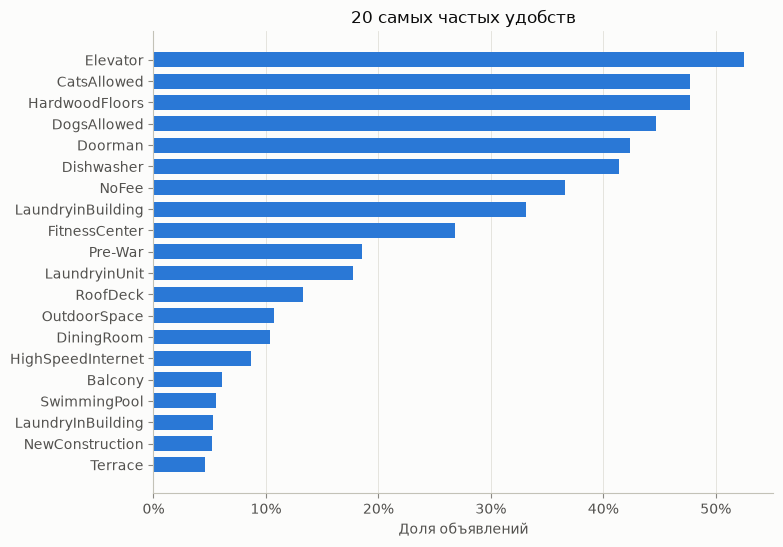

In [8]:
top20 = [feature for feature, _ in feature_counts.most_common(20)]
top20_table = pd.DataFrame(feature_counts.most_common(20), columns=['feature', 'listings'])
top20_table['share'] = top20_table['listings'] / len(df)
top20_table.index = range(1, 21)
display(top20_table.style.format({'listings': '{:,}', 'share': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(8, 6))
ordered = top20_table.iloc[::-1]
ax.barh(ordered['feature'], ordered['share'], height=0.7, color=COLORS[0])
ax.set(title='20 самых частых удобств', xlabel='Доля объявлений')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis='y', visible=False)
plt.show()

## 3.7. Топ-20 только по train

In [9]:
train_counts = Counter(feature for text in train['features_clean'] if text for feature in text.split(','))
top20_train = [feature for feature, _ in train_counts.most_common(20)]
print('Топ-20 только по train - тот же набор:', set(top20_train) == set(top20))
print('Места, где порядок отличается:', [(place, a, b) for place, (a, b) in enumerate(zip(top20, top20_train), start=1) if a != b])
print(f"В train: HardwoodFloors - {train_counts['HardwoodFloors']}, CatsAllowed - {train_counts['CatsAllowed']}")

Топ-20 только по train - тот же набор: True
Места, где порядок отличается: [(2, 'CatsAllowed', 'HardwoodFloors'), (3, 'HardwoodFloors', 'CatsAllowed')]
В train: HardwoodFloors - 17336, CatsAllowed - 17289


**Ответ:** если считать частоты только по train, набор из 20 удобств тот же, а местами меняются лишь `HardwoodFloors` и `CatsAllowed` (17 336 и 17 289 объявлений) - на признаки это не влияет.

## 3.8. 20 новых бинарных признаков

Признак равен 1, если удобство есть в списке объявления, иначе 0. Сравниваем элементы списка целиком, а не ищем подстроку: иначе `Doorman` нашёлся бы и в `VirtualDoorman` или `24/7Doorman`, а это другие удобства.

In [10]:
def add_feature_flags(part, names):
    listing_features = part['features_clean'].str.split(',').apply(set)
    for name in names:
        part[name] = listing_features.apply(lambda items, name=name: int(name in items))


for part in [train, test]:
    add_feature_flags(part, top20)

amenity_stats = pd.DataFrame({
    'доля в train': train[top20].mean(),
    'доля в test': test[top20].mean(),
    'медиана цены с удобством': [train.loc[train[name] == 1, 'price'].median() for name in top20],
    'медиана цены без него': [train.loc[train[name] == 0, 'price'].median() for name in top20],
}, index=top20)
amenity_stats['разница медиан'] = amenity_stats['медиана цены с удобством'] - amenity_stats['медиана цены без него']
display(amenity_stats.style.format({'доля в train': '{:.1%}', 'доля в test': '{:.1%}', 'медиана цены с удобством': '{:,.0f}',
                                    'медиана цены без него': '{:,.0f}', 'разница медиан': '{:+,.0f}'}))

,доля в train,доля в test,медиана цены с удобством,медиана цены без него,разница медиан
Elevator,52.4%,52.9%,"3,400","2,800",+600
CatsAllowed,47.7%,48.4%,"3,250","3,000",+250
HardwoodFloors,47.8%,48.1%,"3,250","3,000",+250
DogsAllowed,44.7%,45.2%,"3,275","3,000",+275
Doorman,42.3%,42.6%,"3,500","2,800",+700
Dishwasher,41.2%,42.5%,"3,480","2,857",+623
NoFee,36.6%,37.4%,"3,370","2,975",+395
LaundryinBuilding,33.1%,33.7%,"3,400","2,995",+405
FitnessCenter,26.7%,27.3%,"3,600","2,900",+700
Pre-War,18.7%,18.2%,"3,000","3,190",-190


Почти каждое удобство из топ-20 связано с более высокой ценой: медиана выше на 900-950 $ у квартир со столовой или террасой (`DiningRoom`, `Terrace`), примерно на 800 $ - со стиральной машиной в квартире (`LaundryinUnit`) или балконом, на 700 $ - с консьержем или фитнес-залом. Исключение - `Pre-War` (дом довоенной постройки): медиана ниже на 190 $. Доли удобств в train и test почти одинаковые (расходятся не больше чем на 1.3 п. п.).

Многие удобства связаны друг с другом: у `CatsAllowed` и `DogsAllowed` корреляция 0.94, у `Elevator` и `Doorman` - 0.62. Поэтому вес удобства в линейной модели - это эффект "при прочих равных", и он может сильно отличаться от простой разницы медиан (п. 4.6).

## 3.9. Итоговый набор признаков

In [11]:
feature_list = top20 + ['bathrooms', 'bedrooms']
X_train, X_test = train[feature_list], test[feature_list]
print(f'Признаков: {len(feature_list)}')
print(feature_list)
X_train.head()

Признаков: 22
['Elevator', 'CatsAllowed', 'HardwoodFloors', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace', 'bathrooms', 'bedrooms']


,Elevator,CatsAllowed,HardwoodFloors,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace,bathrooms,bedrooms
92891,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,1
123761,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1.0,1
92262,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1.0,0
56363,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2.0,2
61895,1,0,1,0,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1.0,1


# 4. Models implementation - Linear regression
## 4.1. Класс линейной регрессии

Модель $\hat y = Xw + b$. Минимизируем

$$Q(w, b) = \frac{1}{2n} \sum_{i=1}^{n} \bigl(x_i^\top w + b - y_i\bigr)^2 + R(w),$$

где $R(w)$ - штраф: у обычной регрессии его нет, он появится в п. 5. Множитель $\tfrac12$ не меняет минимум, но убирает двойку из градиента. В том же масштабе sklearn записывает Lasso и ElasticNet, поэтому параметр `alpha` у наших моделей будет значить то же, что в sklearn.

**SGD.** На каждом шаге берём один объект $i$ (или мини-батч) и шагаем против градиента ошибки на нём:

$$e_i = x_i^\top w + b - y_i, \qquad w \leftarrow w - \eta\, e_i\, x_i, \qquad b \leftarrow b - \eta\, e_i .$$

Эпоха - один проход по всем объектам в случайном порядке. Три детали реализации:
- **Размер шага.** По умолчанию $\eta_0 = 1 / \max_i (1 + \|x_i\|^2)$. С таким шагом ни один объект не "перепрыгивается": после шага по объекту $i$ его ошибка становится $e_i \bigl(1 - \eta(1 + \|x_i\|^2)\bigr)$ - уменьшается, но не меняет знак. Для мини-батча из $m$ объектов шаг можно взять больше: $\eta_0 = m / (L_{\max} + (m-1)L)$, где $L_{\max} = \max_i(1 + \|x_i\|^2)$ - "крутизна" самого крутого объекта, а $L$ - наибольшее собственное число матрицы $\tfrac1n \tilde X^\top \tilde X$ ($\tilde X$ - это $X$ со столбцом единиц для $b$). При $m = 1$ получается прежний шаг, а при больших $m$ - почти $1/L$, как у полного градиентного спуска.
- **Затухание шага.** С постоянным шагом SGD не сходится к минимуму, а "дрожит" вокруг него, потому что градиент по одному объекту шумный. Поэтому шаг уменьшается по эпохам: $\eta_k = \eta_0 / (1 + k)$.
- **Усреднение весов** (Polyak-Ruppert, как `average=True` у `SGDRegressor`): итоговые веса - среднее весов после всех шагов, начиная со второй эпохи. При усреднении шум гасится. Насколько это важно - в п. 4.6.

**Ещё два способа обучения в том же классе:**
- `solver='gd'` - полный (batch) градиентный спуск. Градиент квадратичной функции потерь выражается через матрицу Грама: $\tfrac1n X^\top(Xw - y) = Gw - c$, где $G = \tfrac1n X^\top X$ и $c = \tfrac1n X^\top y$ считаются один раз, поэтому итерация стоит $O(d^2)$ вместо $O(nd)$. Шаг $\eta = 1/L$ ($L$ - наибольшее собственное число $G$) гарантирует сходимость, а ускорение Нестерова (метод моментов) сокращает число итераций на плохо обусловленных задачах в десятки раз.
- `solver='analytical'` - точное решение из п. 1.1 и 1.2.

Свободный член не штрафуется, поэтому в `gd` и `analytical` его можно исключить: при любых $w$ оптимальное $b = \bar y - \bar x^\top w$, и задача сводится к центрированным данным $X - \bar x$ и $y - \bar y$.

Штраф подключается через метод `_penalty`: он возвращает пару $(l_2, l_1)$ для $R(w) = \tfrac{l_2}{2}\|w\|_2^2 + l_1\|w\|_1$. У линейной регрессии это $(0, 0)$, а Ridge, Lasso и ElasticNet переопределят метод в п. 5.

In [12]:
def soft_threshold(w, threshold):
    """Проксимальный шаг для L1-штрафа: сдвигает веса к нулю на threshold, а попавшие в [-threshold, threshold] обнуляет."""
    return np.sign(w) * np.maximum(np.abs(w) - threshold, 0.0)


class MyLinearRegression:
    """Линейная регрессия y ≈ Xw + b.

    Минимизирует Q(w, b) = 1/(2n)·Σ(x_i·w + b − y_i)² + l2/2·||w||² + l1·||w||₁.
    Коэффициенты штрафа (l2, l1) возвращает метод _penalty; у линейной регрессии штрафа нет.

    solver:
        'sgd'        - стохастический градиентный спуск: batch_size=1 - по одному объекту, больше - мини-батчи;
        'gd'         - полный градиентный спуск с ускорением Нестерова;
        'analytical' - решение нормального уравнения (только без L1).
    learning_rate: число или 'auto' - безопасный шаг, вычисленный по данным (см. п. 4.1).
    """

    def __init__(self, solver='sgd', learning_rate='auto', n_epochs=20, batch_size=1, decay=1.0,
                 average=True, max_iter=100_000, tol=1e-7, random_state=RANDOM_STATE):
        self.solver = solver
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs          # sgd: число эпох
        self.batch_size = batch_size      # sgd: размер мини-батча
        self.decay = decay                # sgd: шаг на эпохе k равен learning_rate / (1 + decay·k)
        self.average = average            # sgd: усреднять веса, начиная со второй эпохи
        self.max_iter = max_iter          # gd: максимум итераций
        self.tol = tol                    # gd: остановка, когда веса почти перестали меняться
        self.random_state = random_state  # sgd: зерно для начальных весов и перемешивания

    def _penalty(self, n_samples):
        """Коэффициенты штрафа (l2, l1). Переопределяется в Ridge, Lasso и ElasticNet."""
        return 0.0, 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        l2, l1 = self._penalty(len(y))
        if self.solver == 'sgd':
            self._fit_sgd(X, y, l2, l1)
        elif self.solver == 'gd':
            self._fit_gd(X, y, l2, l1)
        elif self.solver == 'analytical':
            self._fit_analytical(X, y, l2, l1)
        else:
            raise ValueError(f'Неизвестный solver: {self.solver}')
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

    def loss(self, X, y):
        """Значение минимизируемой функции Q на данных (X, y)."""
        y = np.asarray(y, dtype=float)
        l2, l1 = self._penalty(len(y))
        residuals = y - self.predict(X)
        return 0.5 * np.mean(residuals ** 2) + 0.5 * l2 * self.coef_ @ self.coef_ + l1 * np.abs(self.coef_).sum()

    def _fit_sgd(self, X, y, l2, l1):
        n, d = X.shape
        rng = np.random.default_rng(self.random_state) 
        if self.learning_rate == 'auto':
            X1 = np.column_stack([np.ones(n), X])
            L_max = np.max(np.sum(X1 ** 2, axis=1))
            L = np.linalg.eigvalsh(X1.T @ X1 / n)[-1]
            m = min(self.batch_size, n)
            self.learning_rate_ = m / (L_max + (m - 1) * L)
        else:
            self.learning_rate_ = self.learning_rate

        w, b = rng.normal(0, 0.01, size=d), 0.0
        w_sum, b_sum, n_avg = np.zeros(d), 0.0, 0
        self.loss_history_ = []
        for epoch in range(self.n_epochs):
            lr = self.learning_rate_ / (1 + self.decay * epoch)
            shrink = 1 - lr * l2 
            order = rng.permutation(n)
            X_shuffled, y_shuffled = X[order], y[order]
            for start in range(0, n, self.batch_size):
                X_batch = X_shuffled[start:start + self.batch_size]
                errors = X_batch @ w + (b - y_shuffled[start:start + self.batch_size])
                step = lr / len(errors)
                w = shrink * w - step * (X_batch.T @ errors)
                if l1:
                    w = soft_threshold(w, lr * l1)
                b -= step * errors.sum()
                if self.average and epoch > 0:
                    w_sum += w
                    b_sum += b
                    n_avg += 1
            if n_avg:
                self.coef_, self.intercept_ = w_sum / n_avg, b_sum / n_avg
            else:
                self.coef_, self.intercept_ = w.copy(), b
            self.loss_history_.append(self.loss(X, y))
        self.n_iter_ = self.n_epochs

    def _fit_gd(self, X, y, l2, l1):
        n, d = X.shape
        x_mean, y_mean = X.mean(axis=0), y.mean()
        Xc, yc = X - x_mean, y - y_mean
        G, c = Xc.T @ Xc / n, Xc.T @ yc / n
        const = 0.5 * np.mean(yc ** 2)
        if self.learning_rate == 'auto':
            self.learning_rate_ = 1 / (np.linalg.eigvalsh(G)[-1] + l2)  # 1/L
        else:
            self.learning_rate_ = self.learning_rate
        lr = self.learning_rate_

        w = np.zeros(d)
        z, t = w.copy(), 1.0
        self.loss_history_ = []
        for iteration in range(self.max_iter):
            w_new = z - lr * (G @ z - c + l2 * z)
            if l1:
                w_new = soft_threshold(w_new, lr * l1)
            t_new = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
            z = w_new + (t - 1) / t_new * (w_new - w)
            converged = np.max(np.abs(w_new - w)) <= self.tol * (1 + np.max(np.abs(w_new)))
            w, t = w_new, t_new
            self.loss_history_.append(0.5 * w @ G @ w - c @ w + const + 0.5 * l2 * w @ w + l1 * np.abs(w).sum())
            if converged:
                break
        self.n_iter_ = iteration + 1
        self.coef_, self.intercept_ = w, y_mean - x_mean @ w

    def _fit_analytical(self, X, y, l2, l1):
        if l1:
            raise ValueError('С L1-штрафом аналитического решения нет: используйте solver="sgd" или "gd"')
        n, d = X.shape
        x_mean, y_mean = X.mean(axis=0), y.mean()
        Xc, yc = X - x_mean, y - y_mean
        if l2:
            w = np.linalg.solve(Xc.T @ Xc + n * l2 * np.eye(d), Xc.T @ yc)
        else:
            w = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        self.coef_, self.intercept_ = w, y_mean - x_mean @ w
        self.n_iter_ = 0

## 4.2. Детерминированность

**Детерминированная модель** (точнее, детерминированный алгоритм обучения) при одних и тех же данных и гиперпараметрах всегда даёт один и тот же результат: те же веса и те же прогнозы. Аналитическое решение детерминировано само по себе. В SGD два источника случайности: начальные веса и порядок объектов в каждой эпохе (у мини-батчей от порядка зависит и состав батчей).

Чтобы сделать SGD детерминированным, все случайные числа берём из одного генератора с фиксированным зерном - `np.random.default_rng(random_state)` в `_fit_sgd`. Глобальный `np.random` не используется, поэтому результат не зависит и от того, что выполнялось в ноутбуке раньше. Проверим: два запуска с одинаковым `random_state` и один с другим. Чтобы различие было заметнее, обучаем всего две эпохи.

In [13]:
run_a = MyLinearRegression(n_epochs=2, random_state=21).fit(X_train, y_train)
run_b = MyLinearRegression(n_epochs=2, random_state=21).fit(X_train, y_train)
run_c = MyLinearRegression(n_epochs=2, random_state=7).fit(X_train, y_train)

same = np.array_equal(run_a.coef_, run_b.coef_) and run_a.intercept_ == run_b.intercept_
print('random_state одинаковый - веса совпадают до бита:', same)
print(f'random_state другой - веса отличаются до {np.abs(run_a.coef_ - run_c.coef_).max():.2f}')
print(f'MAE на test: {mean_absolute_error(y_test, run_a.predict(X_test)):.3f} (зерно 21) '
      f'и {mean_absolute_error(y_test, run_c.predict(X_test)):.3f} (зерно 7)')

random_state одинаковый - веса совпадают до бита: True
random_state другой - веса отличаются до 54.95
MAE на test: 717.310 (зерно 21) и 717.153 (зерно 7)


**Ответ:** с одинаковым `random_state` веса совпали до последнего бита - алгоритм детерминирован. С другим зерном веса после двух эпох отличаются до 55 $, а MAE - всего на 0.16 $: от зерна зависят конкретные веса, но не качество модели. Оговорка: детерминированность гарантирована на одной машине и одних версиях библиотек. На другом процессоре или с другой сборкой BLAS последние биты сумм с плавающей точкой могут отличаться.

## 4.3. Коэффициент детерминации R²

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2} = 1 - \frac{\text{MSE}}{\operatorname{Var}(y)} .$$

В числителе - ошибка модели, в знаменателе - ошибка наивной модели, которая всем объектам предсказывает среднее. Поэтому:
- $R^2$ - доля дисперсии целевой переменной, которую объясняет модель. В отличие от MAE и RMSE это относительная метрика без единиц измерения: её можно сравнивать между задачами;
- $R^2 = 1$ - идеальный прогноз, $R^2 = 0$ - модель не лучше среднего, $R^2 < 0$ - хуже среднего (так бывает на тестовой выборке или у сломанной модели);
- на test среднее $\bar y$ считается по самому test (так делает и sklearn), поэтому наивная модель со средним из train получает там $R^2$ чуть ниже нуля;
- у МНК со свободным членом на обучающей выборке $R^2$ равен квадрату корреляции между $y$ и $\hat y$.

Метрики пишем сами и сверяем с sklearn.

In [14]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)))


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)) ** 2))


def r2(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot


rng = np.random.default_rng(0)
y_check = rng.normal(3500, 1500, size=1000)
p_check = y_check + rng.normal(0, 900, size=1000)
for name, mine, reference in [('MAE', mae, mean_absolute_error), ('RMSE', rmse, root_mean_squared_error), ('R2', r2, r2_score)]:
    print(f'{name:4s}: свой {mine(y_check, p_check):.10f}, sklearn {reference(y_check, p_check):.10f}')

MAE : свой 742.2930527952, sklearn 742.2930527952
RMSE: свой 920.4707121822, sklearn 920.4707121822
R2  : свой 0.6052992452, sklearn 0.6052992452


## 4.4. Прогнозы и метрики своей модели

In [15]:
start = time.perf_counter()
my_linreg = MyLinearRegression().fit(X_train, y_train)
print(f'Обучение: {time.perf_counter() - start:.1f} с, {my_linreg.n_iter_} эпох, начальный шаг {my_linreg.learning_rate_:.5f}')

pred_train, pred_test = my_linreg.predict(X_train), my_linreg.predict(X_test)
print(f'MAE:  train {mae(y_train, pred_train):.2f}, test {mae(y_test, pred_test):.2f}')
print(f'RMSE: train {rmse(y_train, pred_train):.2f}, test {rmse(y_test, pred_test):.2f}')
print(f'R2:   train {r2(y_train, pred_train):.4f}, test {r2(y_test, pred_test):.4f}')

Обучение: 3.9 с, 20 эпох, начальный шаг 0.00901
MAE:  train 705.83, test 717.34
RMSE: train 1023.17, test 1039.99
R2:   train 0.5768, test 0.5894


**Ответ:** модель объясняет 59 % дисперсии цены на test ($R^2 = 0.589$), средняя ошибка - 717 $, около 20 % средней цены (3529 $). Ошибки на train и test почти равны (RMSE 1023 и 1040), переобучения нет. Для сравнения: в ML_1 линейная регрессия только на `bathrooms` и `bedrooms` давала на test MAE 789, так что 20 признаков-удобств снизили ошибку на 72 $.

## 4.5. LinearRegression из sklearn

In [16]:
sk_linreg = LinearRegression().fit(X_train, y_train)
sk_pred_train, sk_pred_test = sk_linreg.predict(X_train), sk_linreg.predict(X_test)
print(f'MAE:  train {mae(y_train, sk_pred_train):.2f}, test {mae(y_test, sk_pred_test):.2f}')
print(f'RMSE: train {rmse(y_train, sk_pred_train):.2f}, test {rmse(y_test, sk_pred_test):.2f}')
print(f'R2:   train {r2(y_train, sk_pred_train):.4f}, test {r2(y_test, sk_pred_test):.4f}')

MAE:  train 705.82, test 717.32
RMSE: train 1023.17, test 1039.98
R2:   train 0.5768, test 0.5894


## 4.6. Сравнение с sklearn

In [17]:
def compare_metrics(models, X_tr, X_te):
    """MAE, RMSE и R² на train и test для нескольких обученных моделей."""
    rows = {}
    for name, model in models.items():
        p_tr, p_te = model.predict(X_tr), model.predict(X_te)
        rows[name] = {('MAE', 'train'): mae(y_train, p_tr), ('MAE', 'test'): mae(y_test, p_te),
                      ('RMSE', 'train'): rmse(y_train, p_tr), ('RMSE', 'test'): rmse(y_test, p_te),
                      ('R2', 'train'): r2(y_train, p_tr), ('R2', 'test'): r2(y_test, p_te)}
    return pd.DataFrame(rows).T


comparison = compare_metrics({'my_linear_regression': my_linreg, 'sklearn_linear_regression': sk_linreg}, X_train, X_test)
comparison.loc['разница'] = comparison.iloc[0] - comparison.iloc[1]
display(comparison.style.format({column: '{:.6f}' if column[0] == 'R2' else '{:.4f}' for column in comparison.columns}))

weights = pd.DataFrame({'my': my_linreg.coef_, 'sklearn': sk_linreg.coef_}, index=feature_list)
weights.loc['intercept'] = [my_linreg.intercept_, sk_linreg.intercept_]
weights['разница'] = weights['my'] - weights['sklearn']
print(f"Наибольшая разница весов: {weights['разница'].abs().max():.2f}")
display(weights.sort_values('sklearn', key=abs, ascending=False).round(2).T)

Наибольшая разница весов: 1.88


,bathrooms,intercept,Doorman,bedrooms,LaundryinUnit,LaundryInBuilding,Elevator,HighSpeedInternet,FitnessCenter,LaundryinBuilding,Terrace,HardwoodFloors,NoFee,Dishwasher,DogsAllowed,RoofDeck,NewConstruction,DiningRoom,CatsAllowed,OutdoorSpace,Balcony,SwimmingPool,Pre-War
my,1539.61,626.61,620.48,465.46,457.77,-340.34,232.26,-230.05,219.8,-210.69,197.03,-181.72,-169.58,161.31,160.88,-112.93,-109.51,97.37,-74.96,-70.67,-37.68,27.53,-26.68
sklearn,1539.91,626.88,620.43,465.35,457.18,-340.97,230.86,-229.17,220.9,-209.97,197.51,-181.56,-169.79,161.75,159.69,-113.27,-108.76,96.91,-74.23,-70.47,-39.57,26.76,-26.66
разница,-0.30,-0.26,0.04,0.12,0.59,0.62,1.40,-0.88,-1.1,-0.71,-0.48,-0.16,0.21,-0.43,1.19,0.34,-0.74,0.46,-0.73,-0.20,1.88,0.77,-0.03


Зачем затухание шага и усреднение весов: тот же SGD с постоянным шагом и без усреднения.

In [18]:
plain_sgd = MyLinearRegression(decay=0, average=False).fit(X_train, y_train)
display(compare_metrics({'SGD: постоянный шаг': plain_sgd, 'SGD: затухание шага + усреднение': my_linreg,
                         'sklearn': sk_linreg}, X_train, X_test))
print(f'Наибольшая разница весов с sklearn: {np.abs(plain_sgd.coef_ - sk_linreg.coef_).max():.1f} '
      f'против {np.abs(my_linreg.coef_ - sk_linreg.coef_).max():.1f}')

MAE                 RMSE             \
                                     train      test      train       test   
SGD: постоянный шаг               770.7894  784.3076  1066.4630  1079.6278   
SGD: затухание шага + усреднение  705.8282  717.3399  1023.1733  1039.9938   
sklearn                           705.8162  717.3184  1023.1729  1039.9779   

                                      R2          
                                   train    test  
SGD: постоянный шаг               0.5403  0.5575  
SGD: затухание шага + усреднение  0.5768  0.5894  
sklearn                           0.5768  0.5894

Наибольшая разница весов с sklearn: 129.9 против 1.9


**Ответ:** разница со sklearn - сотые доли доллара: MAE на 0.02 $, RMSE на 0.016 $, $R^2$ - в пятом знаке. Веса отличаются не больше чем на 1.9 $ при самих весах в сотни и тысячи долларов. Остаток - шум SGD после 20 эпох; полный градиентный спуск и аналитическое решение совпадают со sklearn ещё точнее (п. 11.3).

Без затухания шага и усреднения SGD до минимума не доходит: MAE на test хуже на 67 $, RMSE - на 40 $, веса отличаются от решения sklearn до 130 $.

Как читать веса: это изменение цены при увеличении признака на единицу при прочих равных - +1540 $ за ванную, +465 $ за спальню, +620 $ за консьержа, +457 $ за стиральную машину в квартире. Часть весов отрицательна, хотя медиана цены с этими удобствами выше (п. 3.8): например, `NoFee` (−170 $) и `LaundryInBuilding` (−341 $). Объявления без комиссии чаще встречаются в больших домах с лифтом и консьержем, и эту надбавку модель уже приписала другим признакам; при прочих равных такие объявления в среднем дешевле. Так что вес - не причинный эффект удобства, а поправка к остальным признакам.

## 4.7. Таблицы результатов

Как в ML_1: по таблице на метрику, столбцы `model`, `train`, `test`. Дальше каждая обученная модель добавляет в них строку.

In [19]:
result_MAE = pd.DataFrame(columns=['model', 'train', 'test']).astype({'train': float, 'test': float})
result_RMSE = result_MAE.copy()
result_R2 = result_MAE.copy()


def add_result(name, pred_train, pred_test, y_true_train=None):
    """Добавляет строку с метриками модели во все три таблицы.

    y_true_train - ответы для train-метрик, если модель обучалась не на всём train (п. 11.2).
    """
    y_true_train = y_train if y_true_train is None else y_true_train
    for table, metric in [(result_MAE, mae), (result_RMSE, rmse), (result_R2, r2)]:
        table.loc[len(table)] = [name, metric(y_true_train, pred_train), metric(y_test, pred_test)]


add_result('my_linear_regression', pred_train, pred_test)
add_result('sklearn_linear_regression', sk_pred_train, sk_pred_test)
display(result_MAE, result_RMSE, result_R2)

,model,train,test
0,my_linear_regression,705.8282,717.3399
1,sklearn_linear_regression,705.8162,717.3184


,model,train,test
0,my_linear_regression,1023.1733,1039.9938
1,sklearn_linear_regression,1023.1729,1039.9779


,model,train,test
0,my_linear_regression,0.5768,0.5894
1,sklearn_linear_regression,0.5768,0.5894


# 5. Regularized models implementation - Ridge, Lasso, ElasticNet
## 5.1. Реализация

Функции потерь - как в sklearn ($n$ - число объектов, $\rho$ - `l1_ratio`):

| модель | минимизируем | $(l_2,\ l_1)$ в `_penalty` |
|---|---|---|
| Ridge | $\frac{1}{2n}\bigl(\lVert y - Xw - b \rVert^2 + \alpha \lVert w \rVert_2^2\bigr)$ | $(\alpha / n,\ 0)$ |
| Lasso | $\frac{1}{2n}\lVert y - Xw - b \rVert^2 + \alpha \lVert w \rVert_1$ | $(0,\ \alpha)$ |
| ElasticNet | $\frac{1}{2n}\lVert y - Xw - b \rVert^2 + \alpha\rho \lVert w \rVert_1 + \frac{\alpha(1 - \rho)}{2} \lVert w \rVert_2^2$ | $(\alpha(1 - \rho),\ \alpha\rho)$ |

Как штрафы входят в шаг (код - в `_fit_sgd` и `_fit_gd` из п. 4.1):
- **L2** добавляет к градиенту $l_2 w$, и шаг становится $w \leftarrow (1 - \eta l_2)\, w - \eta\, \nabla \text{MSE}$: на каждом шаге веса немного уменьшаются (*weight decay*). В аналитическом решении это $\lambda I$ из п. 1.2.
- **L1.** Субградиент $l_1 \operatorname{sign}(w)$ можно добавить к шагу так же, но тогда вес никогда не станет ровно нулём: он будет перескакивать через ноль туда и обратно на $\eta l_1$. Поэтому L1-часть учитываем **проксимальным шагом**: сначала обычный шаг по гладкой части, затем *soft thresholding* $w_j \leftarrow \operatorname{sign}(w_j) \max(\lvert w_j \rvert - \eta l_1,\ 0)$. Это точное решение задачи "остаться рядом с весами после шага, но заплатить $l_1 \lVert w \rVert_1$". Веса, которые шаг не вывел за порог $\pm\eta l_1$, становятся ровно нулём - тот самый механизм отбора признаков из п. 1.3. Полный градиентный спуск с таким шагом называется ISTA, с ускорением Нестерова - FISTA.

**Одно и то же `alpha` у разных моделей значит разное.** У Ridge в sklearn штраф добавляется к *сумме* квадратов ошибок, а у Lasso и ElasticNet - к *средней*. При $n \approx 36$ тыс. объектов `Ridge(alpha=1)` в пересчёте на среднюю ошибку штрафует в $n$ раз слабее, чем `ElasticNet(alpha=1)` свою L2-часть. Сравниваем со sklearn при одинаковых `alpha` - значениях по умолчанию (1.0, у ElasticNet `l1_ratio=0.5`); подбор `alpha` - в п. 8.6.

In [20]:
class MyRidge(MyLinearRegression):
    """Ridge: (||y − Xw − b||² + alpha·||w||²) / (2n), как sklearn.linear_model.Ridge."""

    def __init__(self, alpha=1.0, **kwargs):
        super().__init__(**kwargs)
        self.alpha = alpha

    def _penalty(self, n_samples):
        return self.alpha / n_samples, 0.0


class MyLasso(MyLinearRegression):
    """Lasso: ||y − Xw − b||² / (2n) + alpha·||w||₁, как sklearn.linear_model.Lasso."""

    def __init__(self, alpha=1.0, **kwargs):
        super().__init__(**kwargs)
        self.alpha = alpha

    def _penalty(self, n_samples):
        return 0.0, self.alpha


class MyElasticNet(MyLinearRegression):
    """ElasticNet: ||y − Xw − b||² / (2n) + alpha·ρ·||w||₁ + alpha·(1 − ρ)/2·||w||², ρ = l1_ratio, как в sklearn."""

    def __init__(self, alpha=1.0, l1_ratio=0.5, **kwargs):
        super().__init__(**kwargs)
        self.alpha = alpha
        self.l1_ratio = l1_ratio

    def _penalty(self, n_samples):
        return self.alpha * (1 - self.l1_ratio), self.alpha * self.l1_ratio

## 5.2. Прогнозы своих моделей

In [21]:
my_models = {
    'my_ridge': MyRidge(alpha=1.0),
    'my_lasso': MyLasso(alpha=1.0),
    'my_elastic_net': MyElasticNet(alpha=1.0, l1_ratio=0.5),
}
for name, model in my_models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    print(f'{name}: обучение {time.perf_counter() - start:.1f} с')
display(compare_metrics(my_models, X_train, X_test))

my_ridge: обучение 3.9 с
my_lasso: обучение 5.3 с
my_elastic_net: обучение 5.1 с


MAE                 RMSE                 R2        
                   train      test      train       test   train    test
my_ridge        705.8242  717.3376  1023.1733  1039.9969  0.5768  0.5894
my_lasso        705.4137  717.1301  1023.3348  1040.2877  0.5767  0.5892
my_elastic_net  799.7578  821.9331  1174.2592  1207.9220  0.4426  0.4461

## 5.3. Ridge, Lasso и ElasticNet из sklearn

In [22]:
sk_models = {
    'sklearn_ridge': Ridge(alpha=1.0),
    'sklearn_lasso': Lasso(alpha=1.0),
    'sklearn_elastic_net': ElasticNet(alpha=1.0, l1_ratio=0.5),
}
for model in sk_models.values():
    model.fit(X_train, y_train)
display(compare_metrics(sk_models, X_train, X_test))

MAE                 RMSE                 R2        
                        train      test      train       test   train    test
sklearn_ridge        705.8123  717.3162  1023.1729  1039.9811  0.5768  0.5894
sklearn_lasso        705.4196  717.1426  1023.3725  1040.3067  0.5767  0.5892
sklearn_elastic_net  799.7908  821.9642  1174.2854  1207.9415  0.4426  0.4461

## 5.4. Сравнение с sklearn

In [23]:
rows = {}
for (my_name, mine), reference in zip(my_models.items(), sk_models.values()):
    p_mine, p_ref = mine.predict(X_test), reference.predict(X_test)
    rows[my_name.removeprefix('my_')] = {
        'MAE test: свой': mae(y_test, p_mine), 'MAE test: sklearn': mae(y_test, p_ref),
        'RMSE test: свой': rmse(y_test, p_mine), 'RMSE test: sklearn': rmse(y_test, p_ref),
        'R2 test: свой': r2(y_test, p_mine), 'R2 test: sklearn': r2(y_test, p_ref),
        'наибольшая разница весов': np.abs(mine.coef_ - reference.coef_).max(),
        'нулевых весов (свой / sklearn)': f'{np.sum(mine.coef_ == 0)} / {np.sum(reference.coef_ == 0)}',
    }
display(pd.DataFrame(rows).T)

coef_table = pd.DataFrame({'linear_regression': my_linreg.coef_,
                           **{name.removeprefix('my_'): model.coef_ for name, model in my_models.items()}},
                          index=feature_list)
display(coef_table.sort_values('linear_regression', key=abs, ascending=False).round(1).T)

,MAE test: свой,MAE test: sklearn,RMSE test: свой,RMSE test: sklearn,R2 test: свой,R2 test: sklearn,наибольшая разница весов,нулевых весов (свой / sklearn)
ridge,717.3376,717.3162,1039.9969,1039.9811,0.5894,0.5894,1.8805,0 / 0
lasso,717.1301,717.1426,1040.2877,1040.3067,0.5892,0.5892,10.1372,0 / 0
elastic_net,821.9331,821.9642,1207.922,1207.9415,0.4461,0.4461,0.6548,0 / 0


,bathrooms,Doorman,bedrooms,LaundryinUnit,LaundryInBuilding,Elevator,HighSpeedInternet,FitnessCenter,LaundryinBuilding,Terrace,HardwoodFloors,NoFee,Dishwasher,DogsAllowed,RoofDeck,NewConstruction,DiningRoom,CatsAllowed,OutdoorSpace,Balcony,SwimmingPool,Pre-War
linear_regression,1539.6,620.5,465.5,457.8,-340.3,232.3,-230.0,219.8,-210.7,197.0,-181.7,-169.6,161.3,160.9,-112.9,-109.5,97.4,-75.0,-70.7,-37.7,27.5,-26.7
ridge,1539.4,620.4,465.5,457.7,-340.1,232.2,-230.0,219.8,-210.6,196.8,-181.7,-169.6,161.3,160.7,-112.9,-109.4,97.4,-74.8,-70.6,-37.6,27.6,-26.7
lasso,1538.4,619.8,464.8,449.2,-313.0,224.1,-221.4,208.0,-202.3,152.6,-173.3,-163.6,152.5,104.6,-103.8,-84.8,84.4,-19.0,-50.7,-12.4,12.8,-21.7
elastic_net,461.3,217.8,475.7,135.4,-17.3,136.3,-4.6,123.5,16.6,33.0,-13.4,-1.4,90.9,47.0,14.5,4.5,64.0,37.0,31.5,29.4,30.6,-18.9


**Ответ:** свои модели совпадают со sklearn с той же точностью, что и линейная регрессия: метрики на test - до 0.03 $, веса - до 2 $ у Ridge и ElasticNet и до 10 $ у Lasso.

Что сделала регуляризация при `alpha = 1`:
- **Ridge** почти не отличается от линейной регрессии: в пересчёте на среднюю ошибку коэффициент её штрафа - $\alpha / (2n) \approx 1.4 \cdot 10^{-5}$.
- **Lasso** немного сдвинула веса к нулю, сильнее всего - у пары почти одинаковых признаков `CatsAllowed` и `DogsAllowed` (корреляция 0.94): −75 → −19 и 161 → 105. Обнулять при таком `alpha` нечего: нулевых весов нет ни у своей модели, ни у sklearn.
- **ElasticNet** заметно хуже остальных: MAE 822 вместо 717, $R^2$ 0.45 вместо 0.59. Её L2-часть $\frac{\alpha(1 - \rho)}{2} \lVert w \rVert^2 = 0.25 \lVert w \rVert^2$ добавляется к *средней* ошибке - это сильный штраф. Для одного признака вес умножается примерно на $\operatorname{Var}(x) / (\operatorname{Var}(x) + 0.5)$. У `bathrooms` дисперсия 0.2, поэтому вес уменьшился в 3.3 раза (1540 → 461), а веса редких удобств почти обнулились. Модель недообучилась, но это свойство выбранного `alpha`, а не реализации: sklearn получает то же самое.

## 5.5. Таблицы результатов

In [24]:
for my_name, sk_name in zip(my_models, sk_models):
    for name, model in [(my_name, my_models[my_name]), (sk_name, sk_models[sk_name])]:
        add_result(name, model.predict(X_train), model.predict(X_test))
display(result_MAE, result_RMSE, result_R2)

,model,train,test
0,my_linear_regression,705.8282,717.3399
1,sklearn_linear_regression,705.8162,717.3184
2,my_ridge,705.8242,717.3376
3,sklearn_ridge,705.8123,717.3162
4,my_lasso,705.4137,717.1301
5,sklearn_lasso,705.4196,717.1426
6,my_elastic_net,799.7578,821.9331
7,sklearn_elastic_net,799.7908,821.9642


,model,train,test
0,my_linear_regression,1023.1733,1039.9938
1,sklearn_linear_regression,1023.1729,1039.9779
2,my_ridge,1023.1733,1039.9969
3,sklearn_ridge,1023.1729,1039.9811
4,my_lasso,1023.3348,1040.2877
5,sklearn_lasso,1023.3725,1040.3067
6,my_elastic_net,1174.2592,1207.9220
7,sklearn_elastic_net,1174.2854,1207.9415


,model,train,test
0,my_linear_regression,0.5768,0.5894
1,sklearn_linear_regression,0.5768,0.5894
2,my_ridge,0.5768,0.5894
3,sklearn_ridge,0.5768,0.5894
4,my_lasso,0.5767,0.5892
5,sklearn_lasso,0.5767,0.5892
6,my_elastic_net,0.4426,0.4461
7,sklearn_elastic_net,0.4426,0.4461


## 5.6. Дополнительно: почему Lasso зануляет веса (к вопросу 1.3)

Слева - L1, справа - L2. Серые эллипсы - линии уровня ошибки вокруг решения МНК, синяя область - допустимые веса $\|w\| \le t$, оранжевый эллипс - первый, коснувшийся области; точка касания - решение регуляризованной задачи.

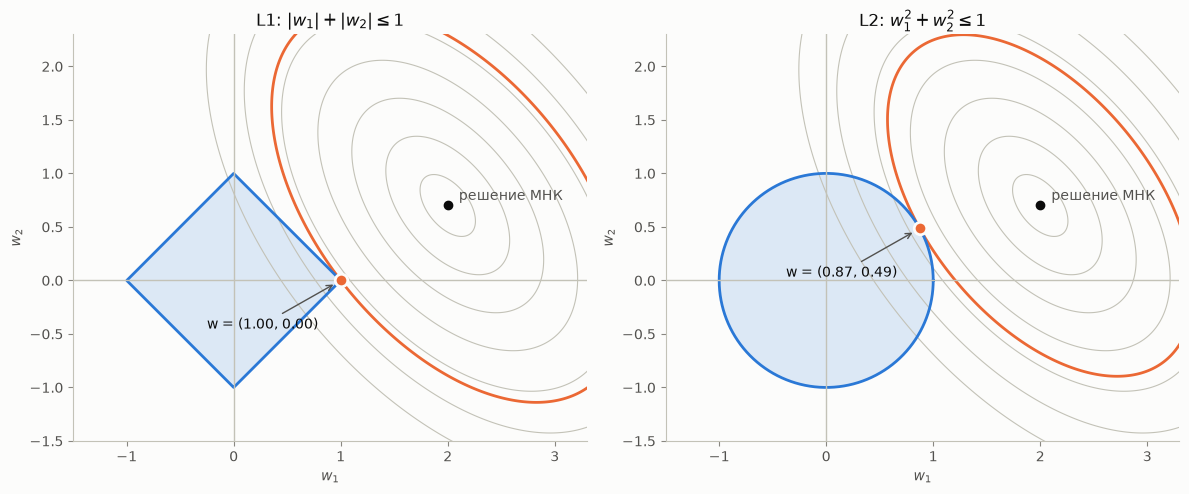

In [25]:
w_ols = np.array([2.0, 0.7])
A = np.array([[1.0, 0.45], [0.45, 0.8]])
error = lambda w: np.einsum('...i,ij,...j->...', w - w_ols, A, w - w_ols)

angles = np.linspace(0, 2 * np.pi, 200_001)
circle = np.column_stack([np.cos(angles), np.sin(angles)])
regions = {
    'L1': (circle / np.abs(circle).sum(axis=1, keepdims=True), r'L1: $|w_1| + |w_2| \leq 1$'),
    'L2': (circle, r'L2: $w_1^2 + w_2^2 \leq 1$'),
}
grid = np.linspace(-1.6, 3.4, 500)
W1, W2 = np.meshgrid(grid, grid)
E = error(np.dstack([W1, W2]))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (boundary, title)) in zip(axes, regions.items()):
    best = boundary[np.argmin(error(boundary))]
    ax.contour(W1, W2, E, levels=[0.05, 0.25, 0.6, 1.1, 1.8, 2.7, 3.8], colors='#c3c2b7', linewidths=0.8)
    ax.contour(W1, W2, E, levels=[error(best)], colors=COLORS[1], linewidths=2)
    ax.fill(boundary[:, 0], boundary[:, 1], color=COLORS[0], alpha=0.15, linewidth=0)
    ax.plot(boundary[:, 0], boundary[:, 1], color=COLORS[0], linewidth=2)
    ax.axhline(0, color='#c3c2b7', linewidth=1)
    ax.axvline(0, color='#c3c2b7', linewidth=1)
    ax.plot(*w_ols, 'o', color=INK, markersize=6)
    ax.annotate('решение МНК', w_ols, xytext=(8, 4), textcoords='offset points', color=INK_SECONDARY)
    ax.plot(*best, 'o', color=COLORS[1], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2, zorder=5)
    ax.annotate(f'w = ({best[0]:.2f}, {best[1]:.2f})', best, xytext=(best[0] - 1.25, best[1] - 0.45), color=INK,
                arrowprops={'arrowstyle': '->', 'color': INK_SECONDARY, 'shrinkB': 6})
    ax.set(title=title, xlabel='$w_1$', ylabel='$w_2$', xlim=(-1.5, 3.3), ylim=(-1.5, 2.3), aspect='equal')
    ax.grid(False)
plt.tight_layout()
plt.show()

С ромбом эллипс касается вершины: решение $(1, 0)$, вес $w_2$ ровно ноль. С кругом - точка касания между осями, оба веса ненулевые. Теперь то же на наших данных: увеличиваем `alpha` у своей Lasso (полный градиентный спуск, `solver='gd'`) и у Lasso из sklearn и считаем нулевые веса.

In [26]:
lasso_path = {}
for alpha in [0.1, 1, 3, 10, 30, 100, 300, 1000]:
    mine = MyLasso(alpha=alpha, solver='gd').fit(X_train, y_train)
    reference = Lasso(alpha=alpha).fit(X_train, y_train)
    lasso_path[alpha] = {
        'ненулевых весов: свой': np.sum(mine.coef_ != 0),
        'ненулевых весов: sklearn': np.sum(reference.coef_ != 0),
        'RMSE test: свой': rmse(y_test, mine.predict(X_test)),
        'RMSE test: sklearn': rmse(y_test, reference.predict(X_test)),
        'оставшиеся признаки': ', '.join(np.array(feature_list)[mine.coef_ != 0]) if np.sum(mine.coef_ != 0) <= 6 else '…',
    }
lasso_path = pd.DataFrame(lasso_path).T
lasso_path.index.name = 'alpha'
display(lasso_path)

,ненулевых весов: свой,ненулевых весов: sklearn,RMSE test: свой,RMSE test: sklearn,оставшиеся признаки
alpha,,,,,
0.1,22,22,1039.993,1039.993,…
1.0,22,22,1040.3054,1040.3067,…
3.0,19,19,1041.466,1041.4656,…
10.0,14,14,1047.8483,1047.8484,…
30.0,6,6,1066.0824,1066.0822,"Elevator, DogsAllowed, Doorman, LaundryinUnit,..."
100.0,3,3,1111.8241,1111.8227,"Doorman, bathrooms, bedrooms"
300.0,2,2,1334.5988,1334.5974,"bathrooms, bedrooms"
1000.0,0,0,1623.2595,1623.2595,


**Ответ:** чем больше `alpha`, тем больше нулевых весов, и своя Lasso при каждом `alpha` обнуляет ровно столько же признаков, сколько sklearn. При `alpha = 100` остаются три признака - `Doorman`, `bathrooms` и `bedrooms`, при 300 - только ванные и спальни, при 1000 - ни одного: модель вырождается в наивное среднее (RMSE 1623, как у `naive_mean` в п. 9). Качество при этом падает плавно: при `alpha = 10` (14 признаков из 22) RMSE на test вырос всего на 8 $. Lasso отбирает признаки по важности: первыми исчезают слабые и дублирующие, последними - ванные и спальни.

# 6. Feature normalization
## 6.1. Когда нормализация обязательна, а когда не нужна

**Нужна (или очень желательна):**
- **Градиентный спуск и SGD.** Если признаки в разных масштабах, линии уровня функции потерь - сильно вытянутые эллипсы. Шаг ограничен самым "крутым" направлением, а вдоль пологих спуск ползёт. Скорость сходимости определяется числом обусловленности матрицы $\tilde X^\top \tilde X$ - в п. 7.3 посчитаем его для наших данных. В п. 8 без нормализации спуск вообще невозможен: масштабы полиномиальных признаков различаются в $10^{10}$ раз.
- **Регуляризация** (Ridge, Lasso, ElasticNet). Штраф зависит от величины весов, а вес - от единиц измерения признака: площадь в м² и в км² даёт веса, отличающиеся в $10^6$ раз, и штрафуются они по-разному. Без нормализации регуляризация "наказывает" признак не за бесполезность, а за единицы измерения.
- **Методы на расстояниях**: kNN, k-means, SVM с RBF-ядром - признак с большим разбросом доминирует в расстоянии.
- **PCA** ищет направления наибольшей дисперсии: без стандартизации главной компонентой станет признак с самыми крупными числами.
- **Нейросети** - по тем же причинам, что и градиентный спуск, плюс насыщение функций активации.

**Не нужна:**
- **Деревья и ансамбли деревьев** (решающее дерево из ML_1, случайный лес, градиентный бустинг): разбиение "признак ≤ порог" не меняется при любом монотонном преобразовании признака.
- **МНК с аналитическим решением**: при линейном преобразовании признака вес масштабируется обратно, и прогнозы не меняются (численно нормализация всё равно полезна - она улучшает обусловленность).
- **Бинарные признаки 0/1** уже в одном масштабе, MinMaxScaler их не меняет.
- **Наивный байесовский классификатор** и другие модели, которые обрабатывают каждый признак отдельно.
- **Когда нужна интерпретация весов в исходных единицах** ("ещё одна ванная - плюс $1500"): можно обучить модель на нормализованных данных и пересчитать веса обратно.

**Важное правило:** параметры нормализации (min и max, среднее и std) считаем только по train и одинаково применяем к train и test - иначе в модель утекает информация из теста.

## 6.2. MinMaxScaler: формула

$$x'_{ij} = \frac{x_{ij} - \min_j}{\max_j - \min_j},$$

где $\min_j$ и $\max_j$ - минимум и максимум признака $j$ на обучающей выборке. На train значения попадают в $[0, 1]$, на test могут выйти за границы. Если признак постоянный ($\max_j = \min_j$), делим не на ноль, а на 1 - так делает и sklearn. Метод чувствителен к выбросам: одна квартира с 10 ванными сжимает все остальные значения `bathrooms` в отрезок $[0, 0.5]$.

## 6.3. Своя реализация MinMaxScaler

In [27]:
class MyMinMaxScaler:
    """x' = (x − min) / (max − min); min и max запоминаются по train."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.data_min_, self.data_max_ = X.min(axis=0), X.max(axis=0)
        data_range = self.data_max_ - self.data_min_
        self.range_ = np.where(data_range == 0, 1.0, data_range)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.data_min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


my_minmax = MyMinMaxScaler().fit(X_train)
X_train_minmax, X_test_minmax = my_minmax.transform(X_train), my_minmax.transform(X_test)

## 6.4. MinMaxScaler из sklearn

In [28]:
sk_minmax = MinMaxScaler().fit(X_train)
sk_X_train_minmax, sk_X_test_minmax = sk_minmax.transform(X_train), sk_minmax.transform(X_test)

## 6.5. Сравнение

In [29]:
def describe_scaled(X_tr, X_te, columns=('bathrooms', 'bedrooms', 'Elevator', 'Terrace')):
    idx = [feature_list.index(column) for column in columns]
    return pd.DataFrame({'min train': X_tr[:, idx].min(axis=0), 'max train': X_tr[:, idx].max(axis=0),
                         'mean train': X_tr[:, idx].mean(axis=0), 'std train': X_tr[:, idx].std(axis=0),
                         'min test': X_te[:, idx].min(axis=0), 'max test': X_te[:, idx].max(axis=0)}, index=columns)


print(f'Наибольшая разница со sklearn: train {np.abs(X_train_minmax - sk_X_train_minmax).max():.1e}, '
      f'test {np.abs(X_test_minmax - sk_X_test_minmax).max():.1e}')
display(describe_scaled(X_train_minmax, X_test_minmax))

Наибольшая разница со sklearn: train 5.6e-17, test 5.6e-17


,min train,max train,mean train,std train,min test,max test
bathrooms,0.0,1.0,0.1192,0.0453,0.0,0.4
bedrooms,0.0,1.0,0.1915,0.1373,0.0,1.0
Elevator,0.0,1.0,0.5235,0.4994,0.0,1.0
Terrace,0.0,1.0,0.0449,0.2071,0.0,1.0


**Ответ:** своя реализация совпадает со sklearn до $6 \cdot 10^{-17}$ - это погрешность округления: sklearn считает $x \cdot \frac{1}{\max - \min} - \frac{\min}{\max - \min}$, а мы $(x - \min) / (\max - \min)$. Заодно видна слабость MinMax: из-за одной квартиры с 10 ваннами признак `bathrooms` на train сжат к нулю - среднее 0.12, стандартное отклонение 0.045, а на test значения не превышают 0.4. Бинарные признаки (`Elevator`, `Terrace`) не изменились.

## 6.6. StandardScaler

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad \mu_j = \frac1n \sum_{i} x_{ij}, \qquad \sigma_j = \sqrt{\frac1n \sum_{i} (x_{ij} - \mu_j)^2} .$$

После преобразования у каждого признака на train среднее 0 и стандартное отклонение 1. Как и в sklearn, $\sigma$ считается с делением на $n$ (`ddof=0`), а нулевое $\sigma$ заменяется на 1. Значения ничем не ограничены, и редкие значения получают большие по модулю $z$: у бинарного признака с долей единиц $p$ единица превращается в $\sqrt{(1 - p)/p}$ - у `Terrace` ($p \approx 4.5\,\%$) это около 4.6.

In [30]:
class MyStandardScaler:
    """z = (x − mean) / std; mean и std (ddof=0) запоминаются по train."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        self.scale_ = np.where(std == 0, 1.0, std)  # постоянный признак не делим на 0
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


my_standard = MyStandardScaler().fit(X_train)
X_train_standard, X_test_standard = my_standard.transform(X_train), my_standard.transform(X_test)

sk_standard = StandardScaler().fit(X_train)
sk_X_train_standard, sk_X_test_standard = sk_standard.transform(X_train), sk_standard.transform(X_test)

print(f'Наибольшая разница со sklearn: train {np.abs(X_train_standard - sk_X_train_standard).max():.1e}, '
      f'test {np.abs(X_test_standard - sk_X_test_standard).max():.1e}')
display(describe_scaled(X_train_standard, X_test_standard))

Наибольшая разница со sklearn: train 0.0e+00, test 0.0e+00


,min train,max train,mean train,std train,min test,max test
bathrooms,-2.6325,19.4503,-1.8422e-16,1.0,-2.6325,6.2006
bedrooms,-1.3945,5.8890,-6.0360e-17,1.0,-1.3945,5.8890
Elevator,-1.0482,0.9540,-6.8199e-17,1.0,-1.0482,0.9540
Terrace,-0.2169,4.6106,1.0975e-17,1.0,-0.2169,4.6106


**Ответ:** совпадение со sklearn точное (разница 0). После стандартизации у всех признаков на train среднее 0 и стандартное отклонение 1, но сами значения не ограничены: квартира с 10 ваннами получает $z = 19.5$, а единица у редкого `Terrace` - 4.6, как и предсказывает формула.

# 7. Fit custom and sklearn models with normalized data

Обучаем все четыре модели - свои и из sklearn - на признаках после MinMaxScaler и после StandardScaler. Используем свои скейлеры: в п. 6 они совпали со sklearn с точностью до округления. Гиперпараметры те же, что в п. 4-5.

In [31]:
def fit_all_models(X_tr, X_te, suffix):
    """Обучает четыре свои модели и четыре модели sklearn, добавляет метрики в таблицы, возвращает модели."""
    pairs = {
        'linear_regression': (MyLinearRegression(), LinearRegression()),
        'ridge': (MyRidge(alpha=1.0), Ridge(alpha=1.0)),
        'lasso': (MyLasso(alpha=1.0), Lasso(alpha=1.0)),
        'elastic_net': (MyElasticNet(alpha=1.0, l1_ratio=0.5), ElasticNet(alpha=1.0, l1_ratio=0.5)),
    }
    fitted = {}
    for name, (mine, reference) in pairs.items():
        for prefix, model in [('my', mine), ('sklearn', reference)]:
            model.fit(X_tr, y_train)
            fitted[f'{prefix}_{name}{suffix}'] = model
            add_result(f'{prefix}_{name}{suffix}', model.predict(X_tr), model.predict(X_te))
    return fitted

## 7.1. MinMaxScaler

In [32]:
start = time.perf_counter()
models_minmax = fit_all_models(X_train_minmax, X_test_minmax, '_minmax')
print(f'Обучение восьми моделей: {time.perf_counter() - start:.0f} с')
display(compare_metrics(models_minmax, X_train_minmax, X_test_minmax))

Обучение восьми моделей: 18 с


MAE                  RMSE             \
                                      train       test      train       test   
my_linear_regression_minmax        705.8667   717.4151  1023.1776  1040.0829   
sklearn_linear_regression_minmax   705.8162   717.3184  1023.1729  1039.9779   
my_ridge_minmax                    706.0040   717.6713  1023.2595  1040.4679   
sklearn_ridge_minmax               705.9428   717.5592  1023.2290  1040.3429   
my_lasso_minmax                    705.7711   717.7040  1023.5917  1041.2570   
sklearn_lasso_minmax               705.7104   717.6440  1023.6077  1041.1959   
my_elastic_net_minmax             1044.5595  1074.7171  1469.5492  1517.8647   
sklearn_elastic_net_minmax        1044.5507  1074.7070  1469.5467  1517.8603   

                                      R2          
                                   train    test  
my_linear_regression_minmax       0.5768  0.5894  
sklearn_linear_regression_minmax  0.5768  0.5894  
my_ridge_minmax                   0.5768  0.5891  
sklearn_ridge_minmax              0.5768  0.5892  
my_lasso_minmax                   0.5765  0.5884  
sklearn_lasso_minmax              0.5765  0.5885  
my_elastic_net_minmax             0.1271  0.1254  
sklearn_elastic_net_minmax        0.1271  0.1254

## 7.2. StandardScaler

In [33]:
start = time.perf_counter()
models_standard = fit_all_models(X_train_standard, X_test_standard, '_standard')
print(f'Обучение восьми моделей: {time.perf_counter() - start:.0f} с')
display(compare_metrics(models_standard, X_train_standard, X_test_standard))

Обучение восьми моделей: 18 с


MAE                 RMSE             \
                                       train      test      train       test   
my_linear_regression_standard       705.8039  717.3129  1023.1732  1039.9978   
sklearn_linear_regression_standard  705.8162  717.3184  1023.1729  1039.9779   
my_ridge_standard                   705.8032  717.3123  1023.1732  1039.9983   
sklearn_ridge_standard              705.8154  717.3178  1023.1729  1039.9784   
my_lasso_standard                   705.6330  717.1790  1023.1992  1040.0561   
sklearn_lasso_standard              705.6381  717.1869  1023.2024  1040.0432   
my_elastic_net_standard             735.8598  751.4955  1067.5960  1092.3058   
sklearn_elastic_net_standard        735.8657  751.4991  1067.5694  1092.2630   

                                        R2          
                                     train    test  
my_linear_regression_standard       0.5768  0.5894  
sklearn_linear_regression_standard  0.5768  0.5894  
my_ridge_standard                   0.5768  0.5894  
sklearn_ridge_standard              0.5768  0.5894  
my_lasso_standard                   0.5768  0.5894  
sklearn_lasso_standard              0.5768  0.5894  
my_elastic_net_standard             0.5393  0.5471  
sklearn_elastic_net_standard        0.5393  0.5471

## 7.3. Результаты в общей таблице

Все строки уже добавлены в `result_MAE`, `result_RMSE` и `result_R2`. Ниже - срез по test: как метрики каждой модели зависят от нормализации.

In [34]:
def scaling_view(table):
    indexed = table.set_index('model')['test']
    view = {}
    for prefix in ['my', 'sklearn']:
        for name in ['linear_regression', 'ridge', 'lasso', 'elastic_net']:
            view[f'{prefix}_{name}'] = {label: indexed[f'{prefix}_{name}{suffix}']
                                        for suffix, label in [('', 'без нормализации'), ('_minmax', 'MinMax'), ('_standard', 'Standard')]}
    return pd.DataFrame(view).T


display(pd.concat({'RMSE test': scaling_view(result_RMSE), 'R2 test': scaling_view(result_R2)}, axis=1))

for label, X in [('без нормализации', X_train.to_numpy(dtype=float)), ('MinMax', X_train_minmax), ('Standard', X_train_standard)]:
    X1 = np.column_stack([np.ones(len(X)), X])
    eigenvalues = np.linalg.eigvalsh(X1.T @ X1 / len(X))
    print(f'{label:17s} число обусловленности матрицы [1, X]ᵀ[1, X]: {eigenvalues[-1] / eigenvalues[0]:7.0f}')

en_weights = pd.DataFrame({
    'без нормализации': my_models['my_elastic_net'].coef_,
    'MinMax (в исходных единицах)': models_minmax['my_elastic_net_minmax'].coef_ / my_minmax.range_,
    'Standard (в исходных единицах)': models_standard['my_elastic_net_standard'].coef_ / my_standard.scale_,
    'LinearRegression': my_linreg.coef_,
}, index=feature_list)
display(en_weights.loc[['bathrooms', 'bedrooms', 'Doorman', 'LaundryinUnit', 'NoFee']].round(1))

RMSE test                        \
                          без нормализации     MinMax   Standard   
my_linear_regression             1039.9938  1040.0829  1039.9978   
my_ridge                         1039.9969  1040.4679  1039.9983   
my_lasso                         1040.2877  1041.2570  1040.0561   
my_elastic_net                   1207.9220  1517.8647  1092.3058   
sklearn_linear_regression        1039.9779  1039.9779  1039.9779   
sklearn_ridge                    1039.9811  1040.3429  1039.9784   
sklearn_lasso                    1040.3067  1041.1959  1040.0432   
sklearn_elastic_net              1207.9415  1517.8603  1092.2630   

                                   R2 test                   
                          без нормализации  MinMax Standard  
my_linear_regression                0.5894  0.5894   0.5894  
my_ridge                            0.5894  0.5891   0.5894  
my_lasso                            0.5892  0.5884   0.5894  
my_elastic_net                      0.4461  0.1254   0.5471  
sklearn_linear_regression           0.5894  0.5894   0.5894  
sklearn_ridge                       0.5894  0.5892   0.5894  
sklearn_lasso                       0.5892  0.5885   0.5894  
sklearn_elastic_net                 0.4461  0.1254   0.5471

без нормализации  число обусловленности матрицы [1, X]ᵀ[1, X]:     483
MinMax            число обусловленности матрицы [1, X]ᵀ[1, X]:    2442
Standard          число обусловленности матрицы [1, X]ᵀ[1, X]:      82


,без нормализации,MinMax (в исходных единицах),Standard (в исходных единицах),LinearRegression
bathrooms,461.3,8.5,1117.7,1539.6
bedrooms,475.7,27.3,354.0,465.5
Doorman,217.8,198.7,366.5,620.5
LaundryinUnit,135.4,184.6,344.1,457.8
NoFee,-1.4,51.5,-61.2,-169.6


**Ответ.** Нормализация по-разному влияет на разные модели:
- **LinearRegression от нормализации не зависит:** у sklearn RMSE одинаковый до последнего знака, у своей модели - с точностью до 0.1 $. МНК инвариантен к линейному преобразованию признаков, веса просто пересчитываются (п. 6.1).
- **Ridge и Lasso** при `alpha = 1` почти не меняются: штраф слабый.
- **ElasticNet меняется сильно:** $R^2$ на test - 0.45 без нормализации, 0.13 после MinMax и 0.55 после StandardScaler. Штраф действует на веса, а вес зависит от масштаба признака. После MinMax `bathrooms` делится на 10 (размах от 0 до 10), её вес в новых единицах становится в 10 раз больше и штрафуется в 10-100 раз сильнее. ElasticNet почти обнуляет главные признаки: в исходных единицах вес ванных - 8.5 $ вместо 1540 $ у линейной регрессии. После StandardScaler все признаки в одном масштабе, и штраф распределяется между ними равномерно: вес ванных - 1118 $.
- **Скорость сходимости SGD** зависит от числа обусловленности: 483 без нормализации, 2442 после MinMax (признаки не центрированы, а `bathrooms` сжат к нулю) и 82 после StandardScaler. Поэтому после MinMax своя модель чуть дальше от решения sklearn: RMSE отличается на 0.1 $ вместо 0.02 $. В п. 11.3 видно, что на стандартизированных данных за 20 эпох сходятся даже мини-батчи по 256 объектов.

# 8. Overfit models
## 8.1. Игрушечный пример переобучения

Полиномиальная регрессия легко переобучается. Повторим эксперимент из ML_1: всего два базовых признака, `bathrooms` и `bedrooms`, и все одночлены от них до 10-й степени. В ML_1 оказалось, что в train всего 50 разных комбинаций (`bathrooms`, `bedrooms`) на 66 столбцов - модели есть где переобучиться.

## 8.2. Полиномиальные признаки степени 10

Отличия от ML_1:
- `include_bias=False`: столбец из единиц не нужен, свободный член есть в самих моделях. Остаётся 65 признаков;
- после `PolynomialFeatures` признаки стандартизуем (своим `MyStandardScaler`, параметры - по train). Без этого градиентный спуск невозможен: `bathrooms¹⁰` доходит до $10^{10}$.

In [35]:
base_features = ['bathrooms', 'bedrooms']
poly = PolynomialFeatures(degree=10, include_bias=False)
P_train = poly.fit_transform(train[base_features])
P_test = poly.transform(test[base_features])
poly_names = poly.get_feature_names_out(base_features)

poly_scaler = MyStandardScaler().fit(P_train)
P_train_std, P_test_std = poly_scaler.transform(P_train), poly_scaler.transform(P_test)

print(f'Признаков: {P_train.shape[1]}; первые: {list(poly_names[:5])}')
print(f'Наибольшее значение: до нормализации {P_train.max():.0e}, после {np.abs(P_train_std).max():.0f}')
print(f'Разных комбинаций (bathrooms, bedrooms) в train: {len(train[base_features].drop_duplicates())}')
print(f'Ранг центрированной матрицы признаков: {np.linalg.matrix_rank(P_train_std - P_train_std.mean(axis=0))} из {P_train.shape[1]}')
print(f'Число обусловленности: {np.linalg.cond(P_train_std):.1e}')

seen_combos = set(map(tuple, train[base_features].to_numpy()))
is_new_combo = np.array([combo not in seen_combos for combo in map(tuple, test[base_features].to_numpy())])
print(f'Квартир в test с комбинацией, которой нет в train: {is_new_combo.sum()}')
display(test.loc[is_new_combo, base_features + ['price']])

Признаков: 65; первые: ['bathrooms', 'bedrooms', 'bathrooms^2', 'bathrooms bedrooms', 'bedrooms^2']
Наибольшее значение: до нормализации 1e+10, после 190
Разных комбинаций (bathrooms, bedrooms) в train: 50
Ранг центрированной матрицы признаков: 49 из 65
Число обусловленности: 1.2e+17
Квартир в test с комбинацией, которой нет в train: 3


,bathrooms,bedrooms,price
104687,3.0,7,6923
18173,3.5,2,11000
28722,3.0,8,9995


**Ответ:** из двух признаков получилось 65, но различных точек всего 50 - столько разных пар (`bathrooms`, `bedrooms`) в train. Поэтому ранг центрированной матрицы - 49 (50 точек минус одна степень свободы на среднее), а число обусловленности - $10^{17}$: матрица вырождена. По п. 1.1 у МНК бесконечно много решений, и все они одинаково хорошо проходят через средние цены 50 комбинаций. В test три квартиры с комбинациями, которых нет в train. Разные решения МНК дают на них совершенно разные прогнозы - именно здесь и проявится переобучение.

## 8.3. Обучение всех моделей на полиномиальных признаках

Сначала проверим SGD из п. 4: его безопасный шаг определяется самым "крутым" объектом.

In [36]:
sgd_poly = MyLinearRegression().fit(P_train_std, y_train)
steepest = np.argmax(np.sum(P_train_std ** 2, axis=1))
steep_baths, steep_beds = train[base_features].iloc[steepest].tolist()
print(f'Начальный шаг SGD: {sgd_poly.learning_rate_:.1e}. Его задаёт квартира с {steep_baths:g} ваннами и {steep_beds:g} спальнями: '
      f'после стандартизации её признаки доходят до {np.abs(P_train_std[steepest]).max():.0f}')
print(f'После 20 эпох: MAE train {mae(y_train, sgd_poly.predict(P_train_std)):.0f}, '
      f'свободный член {sgd_poly.intercept_:.0f} при средней цене {y_train.mean():.0f}')

Начальный шаг SGD: 1.4e-06. Его задаёт квартира с 10 ваннами и 2 спальнями: после стандартизации её признаки доходят до 190
После 20 эпох: MAE train 3069, свободный член 463 при средней цене 3529


С таким шагом SGD за 20 эпох почти не сдвигается с начальной точки, а шаг крупнее разгоняет веса до бесконечности на этой квартире. Поэтому здесь используем другие решатели из того же класса: линейная регрессия и Ridge - аналитическое решение, Lasso и ElasticNet - полный градиентный спуск (FISTA). `alpha` пока те же, что в п. 5 (1.0). Lasso и ElasticNet из sklearn даём `max_iter=100_000`: при значении по умолчанию (1000) покоординатный спуск на таких признаках не успевает сойтись - это проверено ниже.

In [37]:
poly_models = {
    'my_linear_regression_poly10': MyLinearRegression(solver='analytical'),
    'sklearn_linear_regression_poly10': LinearRegression(),
    'my_ridge_poly10': MyRidge(alpha=1.0, solver='analytical'),
    'sklearn_ridge_poly10': Ridge(alpha=1.0),
    'my_lasso_poly10': MyLasso(alpha=1.0, solver='gd'),
    'sklearn_lasso_poly10': Lasso(alpha=1.0, max_iter=100_000),
    'my_elastic_net_poly10': MyElasticNet(alpha=1.0, l1_ratio=0.5, solver='gd'),
    'sklearn_elastic_net_poly10': ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=100_000),
}
start = time.perf_counter()
for model in poly_models.values():
    model.fit(P_train_std, y_train)
print(f'Обучение восьми моделей: {time.perf_counter() - start:.1f} с')

poly_view = compare_metrics(poly_models, P_train_std, P_test_std)
poly_view['ненулевых весов'] = [np.sum(model.coef_ != 0) for model in poly_models.values()]
display(poly_view)

Обучение восьми моделей: 1.7 с


MAE                 RMSE             \
                                     train      test      train       test   
my_linear_regression_poly10       750.8183  804.2024  1068.6299  3980.1517   
sklearn_linear_regression_poly10  751.9530  805.1836  1070.5837  4483.9341   
my_ridge_poly10                   755.6294  767.3084  1076.1274  1092.1786   
sklearn_ridge_poly10              755.6294  767.3084  1076.1274  1092.1786   
my_lasso_poly10                   758.7685  770.6046  1081.9744  1099.1969   
sklearn_lasso_poly10              758.7644  770.5527  1081.9295  1098.6583   
my_elastic_net_poly10             783.1533  794.6689  1115.4210  1129.5022   
sklearn_elastic_net_poly10        783.1540  794.6694  1115.4221  1129.5027   

                                      R2         ненулевых весов  
                                   train    test                  
my_linear_regression_poly10       0.5384 -5.0135              65  
sklearn_linear_regression_poly10  0.5367 -6.6322              65  
my_ridge_poly10                   0.5319  0.5472              65  
sklearn_ridge_poly10              0.5319  0.5472              65  
my_lasso_poly10                   0.5268  0.5414              14  
sklearn_lasso_poly10              0.5268  0.5418              16  
my_elastic_net_poly10             0.4971  0.5157              62  
sklearn_elastic_net_poly10        0.4971  0.5157              62

Lasso: своя модель и sklearn пришли к одному и тому же минимуму? Сравним значение минимизируемой функции $Q$. Для контроля обучим Lasso из sklearn ещё дважды: с очень строгим критерием остановки (`tol=1e-10`; `precompute=True` - покоординатный спуск через матрицу Грама, так быстрее) и с `max_iter` по умолчанию.

In [38]:
def lasso_objective(model, alpha, X, y):
    residuals = np.asarray(y) - model.predict(X)
    return 0.5 * np.mean(residuals ** 2) + alpha * np.abs(model.coef_).sum()


with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ConvergenceWarning)
    lasso_default = Lasso(alpha=1.0).fit(P_train_std, y_train)

lasso_strict = Lasso(alpha=1.0, max_iter=200_000, tol=1e-10, precompute=True).fit(P_train_std, y_train)

for label, model in [('своя Lasso (FISTA)', poly_models['my_lasso_poly10']),
                     ('sklearn, tol=1e-10', lasso_strict),
                     ('sklearn, max_iter=100 000', poly_models['sklearn_lasso_poly10']),
                     ('sklearn, max_iter=1000', lasso_default)]:
    print(f'{label:26s} Q = {lasso_objective(model, 1.0, P_train_std, y_train):.4f}, ненулевых весов: {np.sum(model.coef_ != 0)}')
print('Предупреждения sklearn при max_iter=1000:', [type(w.message).__name__ for w in caught])

своя Lasso (FISTA)         Q = 593071.2595, ненулевых весов: 14
sklearn, tol=1e-10         Q = 593071.2595, ненулевых весов: 14
sklearn, max_iter=100 000  Q = 593117.9852, ненулевых весов: 16
sklearn, max_iter=1000     Q = 593574.3386, ненулевых весов: 26
Предупреждения sklearn при max_iter=1000: ['ConvergenceWarning']


## 8.4. Результаты в общей таблице

In [39]:
for name, model in poly_models.items():
    add_result(name, model.predict(P_train_std), model.predict(P_test_std))
display(result_RMSE.tail(len(poly_models)))

,model,train,test
24,my_linear_regression_poly10,1068.6299,3980.1517
25,sklearn_linear_regression_poly10,1070.5837,4483.9341
26,my_ridge_poly10,1076.1274,1092.1786
27,sklearn_ridge_poly10,1076.1274,1092.1786
28,my_lasso_poly10,1081.9744,1099.1969
29,sklearn_lasso_poly10,1081.9295,1098.6583
30,my_elastic_net_poly10,1115.4210,1129.5022
31,sklearn_elastic_net_poly10,1115.4221,1129.5027


## 8.5. Анализ: где модели переобучились

In [40]:
new_combo_view = test.loc[is_new_combo, base_features + ['price']].copy()
for name in ['my_linear_regression_poly10', 'sklearn_linear_regression_poly10', 'my_ridge_poly10', 'my_lasso_poly10', 'my_elastic_net_poly10']:
    new_combo_view[name.removesuffix('_poly10')] = poly_models[name].predict(P_test_std[is_new_combo]).round().astype(int)
display(new_combo_view)

known = ~is_new_combo
print('RMSE на test без трёх квартир с новыми комбинациями:')
for name in ['my_linear_regression_poly10', 'my_ridge_poly10', 'my_lasso_poly10', 'my_elastic_net_poly10']:
    print(f'  {name:28s} {rmse(y_test[known], poly_models[name].predict(P_test_std[known])):8.1f}'
          f'   (со всеми: {rmse(y_test, poly_models[name].predict(P_test_std)):8.1f})')

,bathrooms,bedrooms,price,my_linear_regression,sklearn_linear_regression,my_ridge,my_lasso,my_elastic_net
104687,3.0,7,6923,67568,-35847,9698,8098,10220
18173,3.5,2,11000,-12950,10319,9533,10175,7942
28722,3.0,8,9995,426087,-466575,22790,-4412,12097


RMSE на test без трёх квартир с новыми комбинациями:
  my_linear_regression_poly10    1079.4   (со всеми:   3980.2)
  my_ridge_poly10                1085.7   (со всеми:   1092.2)
  my_lasso_poly10                1091.4   (со всеми:   1099.2)
  my_elastic_net_poly10          1128.7   (со всеми:   1129.5)


А если полиномиальные признаки не стандартизировать? Обучим Ridge из sklearn с тем же `alpha = 1` на исходных `P_train`. sklearn при этом предупреждает о плохо обусловленной матрице (`LinAlgWarning`) - в этом и суть примера, поэтому предупреждение здесь заглушаем.

In [41]:
from scipy.linalg import LinAlgWarning

with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=LinAlgWarning)
    ridge_unscaled = Ridge(alpha=1.0).fit(P_train, y_train)
add_result('sklearn_ridge_poly10_unscaled', ridge_unscaled.predict(P_train), ridge_unscaled.predict(P_test))
print(f'Ridge(alpha=1) без стандартизации: RMSE train {rmse(y_train, ridge_unscaled.predict(P_train)):.1f}, '
      f'test {rmse(y_test, ridge_unscaled.predict(P_test)):,.1f}, R2 test {r2(y_test, ridge_unscaled.predict(P_test)):.1f}')
print('Прогнозы для трёх квартир с новыми комбинациями:', ', '.join(f'{v:,.0f}' for v in ridge_unscaled.predict(P_test[is_new_combo])))

Ridge(alpha=1) без стандартизации: RMSE train 1069.7, test 27,389.8, R2 test -283.8
Прогнозы для трёх квартир с новыми комбинациями: 151,705, 9,324, 3,015,312


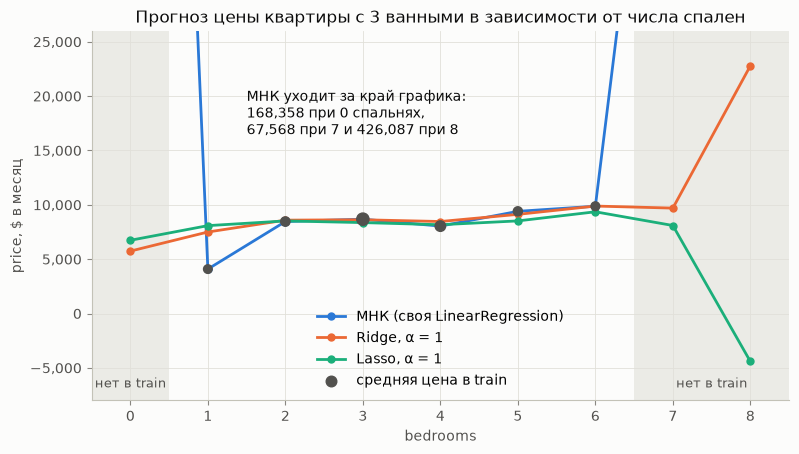

In [42]:
bedrooms_grid = pd.DataFrame({'bathrooms': 3.0, 'bedrooms': np.arange(0, 9)})
grid_std = poly_scaler.transform(poly.transform(bedrooms_grid))
three_baths = train[train['bathrooms'] == 3].groupby('bedrooms')['price'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(9, 4.8))
curves = [('МНК (своя LinearRegression)', 'my_linear_regression_poly10'),
          ('Ridge, α = 1', 'my_ridge_poly10'), ('Lasso, α = 1', 'my_lasso_poly10')]
for color, (label, name) in zip(COLORS, curves):
    ax.plot(bedrooms_grid['bedrooms'], poly_models[name].predict(grid_std), marker='o', markersize=5, color=color, label=label)
ax.scatter(three_baths.index, three_baths['mean'], s=30 + 3 * np.sqrt(three_baths['size']), color=INK_SECONDARY,
           zorder=3, label='средняя цена в train')
ols_curve = poly_models['my_linear_regression_poly10'].predict(grid_std)
ax.text(1.5, 16500, f'МНК уходит за край графика:\n{ols_curve[0]:,.0f} при 0 спальнях,\n'
        f'{ols_curve[7]:,.0f} при 7 и {ols_curve[8]:,.0f} при 8', color=INK)
for left, right in [(-0.5, 0.5), (6.5, 8.5)]:
    ax.axvspan(left, right, color='#e1e0d9', alpha=0.6, linewidth=0)
    ax.text((left + right) / 2, -6800, 'нет в train', ha='center', color=INK_SECONDARY, fontsize=9)
ax.set(title='Прогноз цены квартиры с 3 ванными в зависимости от числа спален',
       xlabel='bedrooms', ylabel='price, $ в месяц', ylim=(-8000, 26000), xlim=(-0.5, 8.5))
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='lower center')
plt.show()

**Ответ.** Переобучилась линейная регрессия без регуляризации, и всё переобучение сосредоточено на трёх квартирах из 12 086:
- На train МНК лучше всех (RMSE 1069): модель проходит ровно через средние цены 50 комбинаций. Без трёх квартир с новыми комбинациями она лучшая и на test (RMSE 1079). Но для этих трёх она предсказывает 67 568 $, −12 950 $ и 426 087 $ при реальных 6923, 11 000 и 9995 $. Из-за трёх прогнозов RMSE на test вырастает до 3980, а $R^2$ падает до −5: модель хуже константы. Между точками данных полином 10-й степени ничем не ограничен. На графике видно, как МНК улетает при 0, 7 и 8 спальнях - там в train нет квартир с тремя ваннами. LinearRegression из sklearn 1.9 отбрасывает малые сингулярные числа (п. 5.2 в ML_1) и выбирает другое решение МНК, но на тех же квартирах тоже ошибается: −35 847 $ и −466 575 $.
- **Регуляризация убирает переобучение:** у Ridge, Lasso и ElasticNet разрыв между train и test - 1-2 %, а прогнозы для новых комбинаций остаются в разумных пределах (Ridge: 9698, 9533 и 22 790 $).
- **Но только вместе со стандартизацией.** Ridge с тем же `alpha = 1` на нестандартизированных признаках переобучается почти как МНК: RMSE на test 27 390, $R^2 = -284$, для квартиры с 3 ваннами и 8 спальнями - 3 млн $. Признаки там доходят до $10^{10}$, веса при старших степенях получаются крошечными, и штраф $\alpha \lVert w \rVert^2$ на них почти не действует. Это случай из п. 6.1, когда без нормализации регуляризация не работает.
- Свои Ridge и ElasticNet совпали со sklearn до последнего знака. Своя Lasso нашла минимум точнее, чем sklearn с критерием остановки по умолчанию: функция потерь у неё меньше, а ненулевых весов 14 - ровно столько же, сколько у sklearn со строгим критерием остановки.

**Лучшая модель по этим результатам** - Ridge с `alpha = 1`: у неё наименьший RMSE на test среди полиномиальных моделей (1092), и она не даёт абсурдных прогнозов. У Lasso один прогноз отрицательный (−4412 $ за квартиру с 3 ваннами и 8 спальнями), ElasticNet надёжна, но недообучена (RMSE 1130). Однако `alpha` здесь не подбиралась, а модель выбрана по test - так честно делать нельзя, поэтому дальше подбираем `alpha` кросс-валидацией.

## 8.6. Подбор `alpha`

Подбираем `alpha` пятикратной кросс-валидацией на train. В каждом фолде `PolynomialFeatures` и стандартизация обучаются только на его обучающей части. Тестовую выборку при выборе не используем. Критерий - средний RMSE по пяти валидационным фолдам. Для наглядности считаем ещё медиану по фолдам и RMSE на обучающей части.

In [43]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_train = train[base_features].to_numpy(dtype=float)
y_train_values = y_train.to_numpy(dtype=float)

cv_folds = []
for fit_idx, val_idx in cv.split(base_train):
    fold_poly, fold_scaler = PolynomialFeatures(degree=10, include_bias=False), MyStandardScaler()
    A = fold_scaler.fit_transform(fold_poly.fit_transform(base_train[fit_idx]))
    B = fold_scaler.transform(fold_poly.transform(base_train[val_idx]))
    cv_folds.append((A, B, fit_idx, val_idx))


def fmt_alpha(alpha):
    """alpha с тремя значащими цифрами без экспоненты: 31.6228 -> '31.6', 1000 -> '1000'."""
    return np.format_float_positional(alpha, precision=3, fractional=False, trim='-')


def cross_validate(make_model, folds=cv_folds, y=y_train_values):
    """RMSE на валидационной и на обучающей части каждого фолда."""
    val_rmse, fit_rmse = [], []
    for A, B, fit_idx, val_idx in folds:
        model = make_model().fit(A, y[fit_idx])
        val_rmse.append(rmse(y[val_idx], model.predict(B)))
        fit_rmse.append(rmse(y[fit_idx], model.predict(A)))
    return np.array(val_rmse), np.array(fit_rmse)


alpha_grids = {
    'ridge': (lambda alpha: MyRidge(alpha=alpha, solver='analytical'), np.logspace(-3, 5, 17)),
    'lasso': (lambda alpha: MyLasso(alpha=alpha, solver='gd'), np.logspace(-1, 3, 9)),
    'elastic_net': (lambda alpha: MyElasticNet(alpha=alpha, l1_ratio=0.5, solver='gd'), np.logspace(-2, 2, 9)),
}
start = time.perf_counter()
cv_rows = []
for model_name, (make_model, grid) in alpha_grids.items():
    for alpha in grid:
        val_rmse, fit_rmse = cross_validate(lambda: make_model(alpha))
        cv_rows.append({'model': model_name, 'alpha': alpha, 'cv_rmse_mean': val_rmse.mean(),
                        'cv_rmse_median': np.median(val_rmse), 'fit_rmse_mean': fit_rmse.mean(), 'fold_rmse': val_rmse.round(0)})
cv_results = pd.DataFrame(cv_rows)
print(f'Кросс-валидация: {time.perf_counter() - start:.0f} с')

ols_val_rmse, _ = cross_validate(lambda: MyLinearRegression(solver='analytical'))
print('МНК без регуляризации, RMSE по фолдам:', ', '.join(f'{value:,.0f}' for value in ols_val_rmse))

ten_baths = np.flatnonzero(train['bathrooms'].to_numpy() == 10)
fold_with_outlier = next(k for k, (*_, val_idx) in enumerate(cv_folds) if np.isin(ten_baths, val_idx).any())
print(f'Квартира с 10 ваннами - в валидационной части фолда {fold_with_outlier + 1}')

best_alpha = cv_results.loc[cv_results.groupby('model', sort=False)['cv_rmse_mean'].idxmin()].set_index('model')
display(best_alpha)

Кросс-валидация: 21 с
МНК без регуляризации, RMSE по фолдам: 14,233, 336,354,394, 1,084, 1,140, 1,070
Квартира с 10 ваннами - в валидационной части фолда 2


,alpha,cv_rmse_mean,cv_rmse_median,fit_rmse_mean,fold_rmse
model,,,,,
ridge,10.0000,3823.5450,1081.1737,1077.7565,"[1092.0, 14807.0, 1081.0, 1065.0, 1073.0]"
lasso,100.0000,1131.8014,1125.0590,1118.1421,"[1128.0, 1203.0, 1125.0, 1097.0, 1106.0]"
elastic_net,31.6228,2110.6964,1348.5613,1345.0552,"[1349.0, 5179.0, 1370.0, 1321.0, 1335.0]"


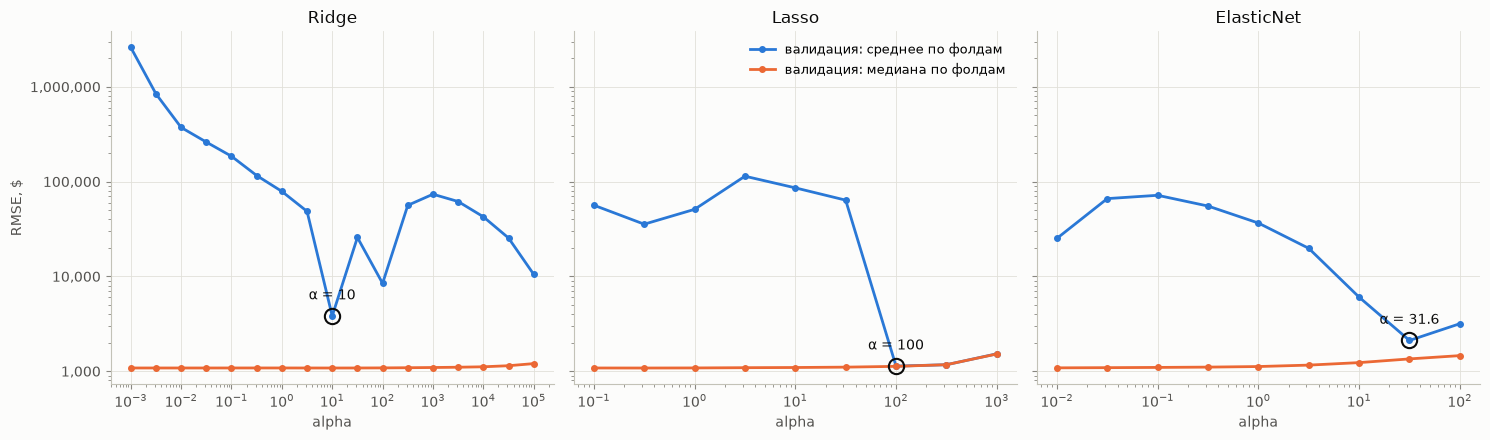

In [44]:
titles = {'ridge': 'Ridge', 'lasso': 'Lasso', 'elastic_net': 'ElasticNet'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (model_name, part) in zip(axes, cv_results.groupby('model', sort=False)):
    ax.plot(part['alpha'], part['cv_rmse_mean'], marker='o', markersize=4, color=COLORS[0], label='валидация: среднее по фолдам')
    ax.plot(part['alpha'], part['cv_rmse_median'], marker='o', markersize=4, color=COLORS[1], label='валидация: медиана по фолдам')
    chosen = best_alpha.loc[model_name]
    ax.plot(chosen['alpha'], chosen['cv_rmse_mean'], 'o', markersize=11, markerfacecolor='none', markeredgecolor=INK, markeredgewidth=1.5)
    ax.annotate(f"α = {fmt_alpha(chosen['alpha'])}", (chosen['alpha'], chosen['cv_rmse_mean']), xytext=(0, 12),
                textcoords='offset points', ha='center', color=INK)
    ax.set(xscale='log', yscale='log', title=titles[model_name], xlabel='alpha')
axes[0].set_ylabel('RMSE, $')
axes[0].yaxis.set_major_formatter(THOUSANDS)
axes[1].legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

Обучаем модели с выбранными `alpha` на всём train и смотрим на test.

In [45]:
best_poly_models = {}
for model_name, (make_model, _) in alpha_grids.items():
    alpha = best_alpha.loc[model_name, 'alpha']
    model = make_model(alpha).fit(P_train_std, y_train)
    name = f'my_{model_name}_poly10_alpha{fmt_alpha(alpha)}'
    best_poly_models[name] = model
    add_result(name, model.predict(P_train_std), model.predict(P_test_std))

best_view = compare_metrics(best_poly_models, P_train_std, P_test_std)
best_view['ненулевых весов'] = [np.sum(model.coef_ != 0) for model in best_poly_models.values()]
best_view['cv_rmse_mean'] = best_alpha['cv_rmse_mean'].to_numpy()
display(best_view)

best_lasso = best_poly_models[f"my_lasso_poly10_alpha{fmt_alpha(best_alpha.loc['lasso', 'alpha'])}"]
print('Lasso оставила признаки:', ', '.join(f'{poly_names[j]} ({best_lasso.coef_[j]:+.1f})' for j in np.flatnonzero(best_lasso.coef_)))

MAE                 RMSE             \
                                    train      test      train       test   
my_ridge_poly10_alpha10          756.9339  768.7850  1077.9399  1093.8493   
my_lasso_poly10_alpha100         786.4374  798.1061  1119.8506  1134.7506   
my_elastic_net_poly10_alpha31.6  961.3951  983.0941  1348.0711  1382.1540   

                                     R2         ненулевых весов cv_rmse_mean  
                                  train    test                               
my_ridge_poly10_alpha10          0.5303  0.5458              65    3823.5450  
my_lasso_poly10_alpha100         0.4931  0.5112               3    1131.8014  
my_elastic_net_poly10_alpha31.6  0.2654  0.2748              57    2110.6964

Lasso оставила признаки: bathrooms (+573.3), bedrooms (+173.6), bathrooms bedrooms (+338.1)


**Ответ.** Средний RMSE по фолдам почти целиком определяется одним фолдом - вторым, где в валидацию попала квартира с 10 ваннами. В обучающей части этого фолда самая большая квартира - с 4.5 ваннами, и полиному 10-й степени приходится экстраполировать до 10: у МНК RMSE на этом фолде - 336 млн $. На остальных фолдах ошибки обычные, около 1080 $, поэтому медиана по фолдам на графике почти ровная. Получается, что критерий "среднее по фолдам" выбирает такое `alpha`, при котором модель не разваливается за пределами данных:
- **Lasso** с этим справляется: при `alpha = 100` она обнуляет все старшие степени и оставляет три признака - `bathrooms`, `bedrooms` и их произведение. Такой модели некуда "улетать": RMSE не выше 1203 ни на одном фолде, в среднем 1132.
- **Ridge** обнулять веса не умеет, и второй фолд остаётся плохим при любом `alpha`. Выбранное `alpha = 10` - просто удачный провал на неровной кривой; на втором фолде RMSE всё равно 14 807.
- **ElasticNet** получает приличную ошибку на втором фолде только при `alpha ≈ 32`, но с таким штрафом недообучается на всех остальных: RMSE на test 1382, $R^2$ 0.27.

**Итог п. 8:** по кросс-валидации лучшая полиномиальная модель - **Lasso с `alpha = 100`**. Она единственная надёжна на всех фолдах, а оставленные ею признаки легко интерпретировать. На test она немного уступает Ridge (1135 против 1094), потому что в test нет квартир за пределами диапазона train, но заранее этого не знать, и кросс-валидация честно предупреждает о риске. В п. 11.2 выяснится, что после удаления из train ошибочной квартиры с 10 ваннами кросс-валидация выбирает совсем другие `alpha`, а её оценка совпадает с test. И все полиномиальные модели хуже обычной линейной регрессии на 22 признаках (RMSE 1040): два признака плохо описывают цену, какой бы гибкой ни была функция от них.

# 9. Native models

Наивная модель всем объектам предсказывает одну константу, посчитанную по train:
- **среднее** - лучшая константа для MSE и RMSE: $\frac{d}{dc}\sum_i (y_i - c)^2 = 0 \Rightarrow c = \bar y$;
- **медиана** - лучшая константа для MAE: производная $\sum_i \lvert y_i - c \rvert$ равна $\#\{y_i < c\} - \#\{y_i > c\}$ и обращается в ноль, когда по обе стороны от $c$ одинаково объектов.

In [46]:
for name, value in [('naive_mean', y_train.mean()), ('naive_median', y_train.median())]:
    p_tr, p_te = np.full(len(y_train), value), np.full(len(y_test), value)
    add_result(name, p_tr, p_te)
    print(f'{name}: прогноз {value:.1f}; MAE test {mae(y_test, p_te):.5f}, RMSE test {rmse(y_test, p_te):.5f}, '
          f'R2 train {r2(y_train, p_tr):.4f}, R2 test {r2(y_test, p_te):.4f}')

naive_mean: прогноз 3528.8; MAE test 1156.35067, RMSE test 1623.25952, R2 train 0.0000, R2 test -0.0002
naive_median: прогноз 3150.0; MAE test 1107.49992, RMSE test 1672.63357, R2 train -0.0580, R2 test -0.0620


**Ответ:** MAE наивных моделей на test совпадает с результатами ML_1 (1156.35 и 1107.50). Как и предсказывает теория, медиана лучше среднего по MAE (1107 против 1156), а среднее лучше по RMSE (1623 против 1673). $R^2$ среднего на train ровно 0 - так устроено определение $R^2$; на test он чуть ниже нуля, потому что среднее test немного отличается от среднего train. Лучшие модели на 22 признаках снижают MAE на 35 % относительно медианы, а RMSE - на 36 % относительно среднего.

# 10. Compare results
## 10.1. Итоговые таблицы

In [47]:
print('MAE')
display(result_MAE)
print('RMSE')
display(result_RMSE)
print('R2')
display(result_R2)

MAE


,model,train,test
0,my_linear_regression,705.8282,717.3399
1,sklearn_linear_regression,705.8162,717.3184
2,my_ridge,705.8242,717.3376
3,sklearn_ridge,705.8123,717.3162
4,my_lasso,705.4137,717.1301
5,sklearn_lasso,705.4196,717.1426
6,my_elastic_net,799.7578,821.9331
7,sklearn_elastic_net,799.7908,821.9642
8,my_linear_regression_minmax,705.8667,717.4151
9,sklearn_linear_regression_minmax,705.8162,717.3184


RMSE


,model,train,test
0,my_linear_regression,1023.1733,1039.9938
1,sklearn_linear_regression,1023.1729,1039.9779
2,my_ridge,1023.1733,1039.9969
3,sklearn_ridge,1023.1729,1039.9811
4,my_lasso,1023.3348,1040.2877
5,sklearn_lasso,1023.3725,1040.3067
6,my_elastic_net,1174.2592,1207.9220
7,sklearn_elastic_net,1174.2854,1207.9415
8,my_linear_regression_minmax,1023.1776,1040.0829
9,sklearn_linear_regression_minmax,1023.1729,1039.9779


R2


,model,train,test
0,my_linear_regression,0.5768,0.5894
1,sklearn_linear_regression,0.5768,0.5894
2,my_ridge,0.5768,0.5894
3,sklearn_ridge,0.5768,0.5894
4,my_lasso,0.5767,0.5892
5,sklearn_lasso,0.5767,0.5892
6,my_elastic_net,0.4426,0.4461
7,sklearn_elastic_net,0.4426,0.4461
8,my_linear_regression_minmax,0.5768,0.5894
9,sklearn_linear_regression_minmax,0.5768,0.5894


Те же числа в одной таблице, по возрастанию RMSE на test:

In [48]:
summary = pd.concat({'MAE': result_MAE.set_index('model'), 'RMSE': result_RMSE.set_index('model'),
                     'R2': result_R2.set_index('model')}, axis=1)
summary = summary.sort_values(('RMSE', 'test'))
display(summary)

MAE                  RMSE  \
                                        train       test      train   
model                                                                 
sklearn_linear_regression            705.8162   717.3184  1023.1729   
sklearn_linear_regression_minmax     705.8162   717.3184  1023.1729   
sklearn_linear_regression_standard   705.8162   717.3184  1023.1729   
sklearn_ridge_standard               705.8154   717.3178  1023.1729   
sklearn_ridge                        705.8123   717.3162  1023.1729   
my_linear_regression                 705.8282   717.3399  1023.1733   
my_ridge                             705.8242   717.3376  1023.1733   
my_linear_regression_standard        705.8039   717.3129  1023.1732   
my_ridge_standard                    705.8032   717.3123  1023.1732   
sklearn_lasso_standard               705.6381   717.1869  1023.2024   
my_lasso_standard                    705.6330   717.1790  1023.1992   
my_linear_regression_minmax          705.8667   717.4151  1023.1776   
my_lasso                             705.4137   717.1301  1023.3348   
sklearn_lasso                        705.4196   717.1426  1023.3725   
sklearn_ridge_minmax                 705.9428   717.5592  1023.2290   
my_ridge_minmax                      706.0040   717.6713  1023.2595   
sklearn_lasso_minmax                 705.7104   717.6440  1023.6077   
my_lasso_minmax                      705.7711   717.7040  1023.5917   
my_ridge_poly10                      755.6294   767.3084  1076.1274   
sklearn_ridge_poly10                 755.6294   767.3084  1076.1274   
sklearn_elastic_net_standard         735.8657   751.4991  1067.5694   
my_elastic_net_standard              735.8598   751.4955  1067.5960   
my_ridge_poly10_alpha10              756.9339   768.7850  1077.9399   
sklearn_lasso_poly10                 758.7644   770.5527  1081.9295   
my_lasso_poly10                      758.7685   770.6046  1081.9744   
my_elastic_net_poly10                783.1533   794.6689  1115.4210   
sklearn_elastic_net_poly10           783.1540   794.6694  1115.4221   
my_lasso_poly10_alpha100             786.4374   798.1061  1119.8506   
my_elastic_net                       799.7578   821.9331  1174.2592   
sklearn_elastic_net                  799.7908   821.9642  1174.2854   
my_elastic_net_poly10_alpha31.6      961.3951   983.0941  1348.0711   
sklearn_elastic_net_minmax          1044.5507  1074.7070  1469.5467   
my_elastic_net_minmax               1044.5595  1074.7171  1469.5492   
naive_mean                          1124.7703  1156.3507  1572.8754   
naive_median                        1073.7943  1107.4999  1617.8518   
my_linear_regression_poly10          750.8183   804.2024  1068.6299   
sklearn_linear_regression_poly10     751.9530   805.1836  1070.5837   
sklearn_ridge_poly10_unscaled        751.4133  1023.4301  1069.7452   

                                                    R2            
                                          test   train      test  
model                                                             
sklearn_linear_regression            1039.9779  0.5768    0.5894  
sklearn_linear_regression_minmax     1039.9779  0.5768    0.5894  
sklearn_linear_regression_standard   1039.9779  0.5768    0.5894  
sklearn_ridge_standard               1039.9784  0.5768    0.5894  
sklearn_ridge                        1039.9811  0.5768    0.5894  
my_linear_regression                 1039.9938  0.5768    0.5894  
my_ridge                             1039.9969  0.5768    0.5894  
my_linear_regression_standard        1039.9978  0.5768    0.5894  
my_ridge_standard                    1039.9983  0.5768    0.5894  
sklearn_lasso_standard               1040.0432  0.5768    0.5894  
my_lasso_standard                    1040.0561  0.5768    0.5894  
my_linear_regression_minmax          1040.0829  0.5768    0.5894  
my_lasso                             1040.2877  0.5767    0.5892  
sklearn_lasso                        1040.3067  0.5767    

## 10.2. Лучшая модель

In [49]:
for metric, table, pick in [('MAE', result_MAE, 'idxmin'), ('RMSE', result_RMSE, 'idxmin'), ('R2', result_R2, 'idxmax')]:
    best = table.loc[getattr(table['test'], pick)()]
    print(f"Лучшая по {metric} на test: {best['model']} ({best['test']:.4f})")

families = (['my_linear_regression_standard', 'my_ridge_standard', 'my_lasso_standard', 'my_elastic_net_standard']
            + list(best_poly_models) + ['naive_mean', 'naive_median'])
display(summary.loc[families])

Лучшая по MAE на test: my_lasso (717.1301)
Лучшая по RMSE на test: sklearn_linear_regression (1039.9779)
Лучшая по R2 на test: sklearn_linear_regression (0.5894)


MAE                  RMSE             \
                                     train       test      train       test   
model                                                                         
my_linear_regression_standard     705.8039   717.3129  1023.1732  1039.9978   
my_ridge_standard                 705.8032   717.3123  1023.1732  1039.9983   
my_lasso_standard                 705.6330   717.1790  1023.1992  1040.0561   
my_elastic_net_standard           735.8598   751.4955  1067.5960  1092.3058   
my_ridge_poly10_alpha10           756.9339   768.7850  1077.9399  1093.8493   
my_lasso_poly10_alpha100          786.4374   798.1061  1119.8506  1134.7506   
my_elastic_net_poly10_alpha31.6   961.3951   983.0941  1348.0711  1382.1540   
naive_mean                       1124.7703  1156.3507  1572.8754  1623.2595   
naive_median                     1073.7943  1107.4999  1617.8518  1672.6336   

                                     R2          
                                  train    test  
model                                            
my_linear_regression_standard    0.5768  0.5894  
my_ridge_standard                0.5768  0.5894  
my_lasso_standard                0.5768  0.5894  
my_elastic_net_standard          0.5393  0.5471  
my_ridge_poly10_alpha10          0.5303  0.5458  
my_lasso_poly10_alpha100         0.4931  0.5112  
my_elastic_net_poly10_alpha31.6  0.2654  0.2748  
naive_mean                       0.0000 -0.0002  
naive_median                    -0.0580 -0.0620

**Ответ:** лучшие - линейная регрессия, Ridge и Lasso на 22 признаках (20 удобств + `bathrooms` + `bedrooms`): на test MAE ≈ 717 $, RMSE ≈ 1040 $, $R^2 \approx 0.589$. Формально по MAE лучшая - своя Lasso без нормализации (717.13), по RMSE и $R^2$ - LinearRegression из sklearn (1039.98 и 0.5894). Но разница между этими моделями - десятые доли доллара, во много раз меньше статистического шума: при смене обучающей выборки RMSE меняется на ±18 $ (п. 10.3). Нормализация на их качество не влияет, а регуляризация при `alpha = 1` почти ничего не меняет: признаков мало (22 на 36 тысяч объектов), и переобучаться модели не на чем.

Остальные модели хуже по понятным причинам:
- ElasticNet с `alpha = 1` недообучена из-за сильного штрафа (п. 5.4 и 7.3);
- регуляризованные полиномиальные модели на двух признаках проигрывают даже с лучшим `alpha` (RMSE на test 1092-1135 у Ridge и Lasso): удобства квартиры дают больше, чем сложная форма зависимости от числа комнат;
- МНК на полиномах и Ridge на нестандартизированных полиномиальных признаках переобучены (п. 8.5) и на test хуже наивной модели.

По MAE ещё немного выигрывает модель, обученная на $\log(\text{price})$ (п. 11.1: 705.5).

## 10.3. Самая стабильная модель

Стабильность понимаем двояко: (1) качество на новых данных не хуже, чем на обучающих, - небольшой разрыв между train и test; (2) качество мало меняется при смене обучающей выборки - небольшой разброс RMSE по пяти фолдам кросс-валидации на train. Для кросс-валидации линейных моделей на 22 признаках берём точные решатели (`analytical`, `gd`): минимум у них тот же, что у SGD, а считаются они в сотни раз быстрее.

In [50]:
X_train_values = X_train.to_numpy(dtype=float)
linear_folds = []
for fit_idx, val_idx in cv.split(X_train_values):
    fold_scaler = MyStandardScaler().fit(X_train_values[fit_idx])
    linear_folds.append((fold_scaler.transform(X_train_values[fit_idx]), fold_scaler.transform(X_train_values[val_idx]), fit_idx, val_idx))


class NaiveMean:
    def fit(self, X, y):
        self.value_ = np.mean(y)
        return self

    def predict(self, X):
        return np.full(len(X), self.value_)


candidates = {
    'my_linear_regression_standard': (lambda: MyLinearRegression(solver='analytical'), linear_folds),
    'my_ridge_standard': (lambda: MyRidge(alpha=1.0, solver='analytical'), linear_folds),
    'my_lasso_standard': (lambda: MyLasso(alpha=1.0, solver='gd'), linear_folds),
    'my_elastic_net_standard': (lambda: MyElasticNet(alpha=1.0, solver='gd'), linear_folds),
    'my_linear_regression_poly10': (lambda: MyLinearRegression(solver='analytical'), cv_folds),
    'my_ridge_poly10': (lambda: MyRidge(alpha=1.0, solver='analytical'), cv_folds),
    'naive_mean': (NaiveMean, linear_folds),
}
for name, model in best_poly_models.items():
    model_name = name.removeprefix('my_').split('_poly10')[0]
    candidates[name] = ((lambda make=alpha_grids[model_name][0], alpha=model.alpha: make(alpha)), cv_folds)
stability = {}
for name, (make_model, folds) in candidates.items():
    val_rmse, _ = cross_validate(make_model, folds)
    rmse_row = result_RMSE.set_index('model').loc[name]
    stability[name] = {'RMSE train': rmse_row['train'], 'RMSE test': rmse_row['test'],
                       'test / train': rmse_row['test'] / rmse_row['train'],
                       'CV RMSE: среднее': val_rmse.mean(), 'CV RMSE: std': val_rmse.std(), 'CV RMSE: max': val_rmse.max()}
stability = pd.DataFrame(stability).T
display(stability.style.format({column: '{:.4f}' if column == 'test / train' else '{:,.1f}' for column in stability.columns}))

,RMSE train,RMSE test,test / train,CV RMSE: среднее,CV RMSE: std,CV RMSE: max
my_linear_regression_standard,"1,023.2","1,040.0",1.0164,"1,024.1",17.8,"1,048.6"
my_ridge_standard,"1,023.2","1,040.0",1.0164,"1,024.1",17.8,"1,048.6"
my_lasso_standard,"1,023.2","1,040.1",1.0165,"1,024.1",17.8,"1,048.6"
my_elastic_net_standard,"1,067.6","1,092.3",1.0231,"1,068.0",17.5,"1,088.5"
my_linear_regression_poly10,"1,068.6","3,980.2",3.7245,"67,274,384.2","134,540,005.0","336,354,393.9"
my_ridge_poly10,"1,076.1","1,092.2",1.0149,"78,824.8","155,495.1","389,815.1"
naive_mean,"1,572.9","1,623.3",1.0320,"1,572.8",20.6,"1,598.2"
my_ridge_poly10_alpha10,"1,077.9","1,093.8",1.0148,"3,823.5","5,491.6","14,806.6"
my_lasso_poly10_alpha100,"1,119.9","1,134.8",1.0133,"1,131.8",37.3,"1,202.7"
my_elastic_net_poly10_alpha31.6,"1,348.1","1,382.2",1.0253,"2,110.7","1,534.5","5,179.5"


**Ответ.**
- **Разрыв между train и test** у всех моделей, кроме МНК на полиномах, небольшой: RMSE на test больше, чем на train, на 1.3-3 %. У переобученного МНК на полиномах - в 3.7 раза.
- **Разброс по фолдам** у линейных моделей на 22 признаках - ±17.8 $ при среднем 1024 $ (1.7 %). Почти такой же разброс у наивной модели (±20.6 $): это разброс самих данных, а не моделей. LinearRegression, Ridge и Lasso здесь неразличимы. На полиномиальных признаках все модели, кроме Lasso с `alpha = 100`, "взрываются" на втором фолде: разброс от тысяч долларов (ElasticNet и Ridge с подобранным `alpha`) до сотен миллионов (МНК). У Lasso с `alpha = 100` - ±37 $, худший фолд - 1203 $.

**Самая стабильная модель - Lasso.** На 22 признаках она так же стабильна, как LinearRegression и Ridge, а на полиномиальных признаках только она выдерживает все разбиения: L1-штраф выключает лишние признаки, и модели некуда "улетать". Самая нестабильная - линейная регрессия без регуляризации на полиномиальных признаках.

# 11. Addition task
## 11.1. Логарифм целевой переменной

В ML_1 выяснили, что цена скошена вправо (асимметрия 2.0), а её логарифм распределён почти симметрично (0.59). Обучим ту же линейную регрессию (SGD, стандартизированные 22 признака) на $z = \log(\text{price})$ и вернёмся к ценам обратным преобразованием $e^{\hat z}$.

Тонкость: $e^{\hat z}$ оценивает не среднее, а *медиану* цены (точнее, среднее геометрическое): $e^{\mathbb{E}[\log y]} \le \mathbb{E}[y]$. Поэтому прогнозы систематически занижены. Стандартная поправка - **smearing** (Duan, 1983): умножить прогноз на $\frac1n\sum_i e^{r_i}$, где $r_i$ - ошибки модели на train в логарифмической шкале.

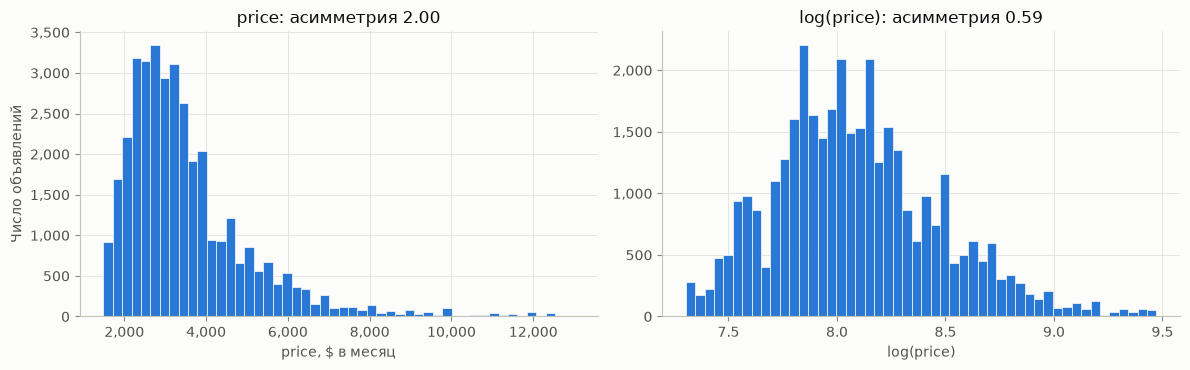

Поправка smearing: 1.0326


,MAE test,RMSE test,R2 test,средний прогноз test,медианный прогноз test
обычная цель,717.3129,1039.9978,0.5894,3549.8331,3182.7304
"log(price), exp",705.5038,1046.5012,0.5843,3440.4760,3057.5588
"log(price), exp · smearing",717.6112,1039.7965,0.5896,3552.7466,3157.3340


Для сравнения в test: средняя цена 3554, медианная 3150


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(y_train, bins=50, color=COLORS[0], edgecolor=SURFACE, linewidth=0.5)
axes[0].set(title=f'price: асимметрия {y_train.skew():.2f}', xlabel='price, $ в месяц', ylabel='Число объявлений')
axes[0].xaxis.set_major_formatter(THOUSANDS)
axes[1].hist(np.log(y_train), bins=50, color=COLORS[0], edgecolor=SURFACE, linewidth=0.5)
axes[1].set(title=f'log(price): асимметрия {np.log(y_train).skew():.2f}', xlabel='log(price)')
for ax in axes:
    ax.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()

log_model = MyLinearRegression().fit(X_train_standard, np.log(y_train))
log_pred_train, log_pred_test = np.exp(log_model.predict(X_train_standard)), np.exp(log_model.predict(X_test_standard))
smearing = np.mean(np.exp(np.log(y_train) - log_model.predict(X_train_standard)))
print(f'Поправка smearing: {smearing:.4f}')

add_result('my_linear_regression_log_target', log_pred_train, log_pred_test)
add_result('my_linear_regression_log_target_smearing', log_pred_train * smearing, log_pred_test * smearing)

base_model = models_standard['my_linear_regression_standard']
log_view = {'обычная цель': (base_model.predict(X_train_standard), base_model.predict(X_test_standard)),
            'log(price), exp': (log_pred_train, log_pred_test),
            'log(price), exp · smearing': (log_pred_train * smearing, log_pred_test * smearing)}
display(pd.DataFrame({name: {'MAE test': mae(y_test, p_te), 'RMSE test': rmse(y_test, p_te), 'R2 test': r2(y_test, p_te),
                             'средний прогноз test': p_te.mean(), 'медианный прогноз test': np.median(p_te)}
                      for name, (p_tr, p_te) in log_view.items()}).T)
print(f'Для сравнения в test: средняя цена {y_test.mean():.0f}, медианная {y_test.median():.0f}')

**Ответ:** логарифм не делает модель однозначно лучше - он меняет то, что модель предсказывает:
- **Без поправки** $e^{\hat z}$ предсказывает скорее медиану, чем среднее: средний прогноз на test 3440 $ при средней цене 3554 $. Поэтому MAE, которую минимизирует медиана, стал лучше на 12 $ (705.5 против 717.3), а RMSE - хуже на 6.5 $ (1046.5).
- **С поправкой smearing** (прогноз × 1.033) средний прогноз возвращается к среднему (3553 $), и метрики почти такие же, как у обычной модели: RMSE 1039.8 (на 0.2 $ лучше), MAE 717.6.

Итог: если важна MAE (типичная ошибка в долларах), модель стоит учить на $\log(\text{price})$ без поправки; если важны RMSE или несмещённое среднее - на исходной цене или с поправкой smearing. Большого эффекта и не стоило ждать: выбросы цены удалены ещё в ML_1, и асимметрия уже умеренная (2.0).

## 11.2. Выбросы - только из обучающей выборки

**Почему только из train.** Тестовая выборка изображает новые данные, на которых модель будет работать. Среди будущих объявлений тоже будут странные - их нельзя выбросить, на них всё равно придётся давать прогноз. Если почистить test, метрики станут лучше, но это будет оценка на другом, "удобном" распределении, а не честная оценка качества: по сути, подгонка теста под модель. Выбросы в train - другое дело: это решение о том, на чём учиться, и оно законно, если улучшает прогноз на нетронутом test. Кроме того, правило отбора (порог, модель для остатков) тоже должно строиться только по train.

Пробуем два вида выбросов:
1. **Ошибка в данных** - квартира с 10 ванными и 2 спальнями за 3600 $. Для линейной модели на 22 признаках это одна точка из 36 тысяч, а для полинома 10-й степени - главный источник нестабильности из п. 8.6.
2. **Статистические выбросы** - объявления, цена которых плохо объясняется признаками: ошибка модели из п. 7.2 на train больше трёх стандартных отклонений.

In [52]:
clean_mask = (train['bathrooms'] != 10).to_numpy()
clean_folds = []
for fit_idx, val_idx in cv.split(base_train[clean_mask]):
    fold_poly, fold_scaler = PolynomialFeatures(degree=10, include_bias=False), MyStandardScaler()
    A = fold_scaler.fit_transform(fold_poly.fit_transform(base_train[clean_mask][fit_idx]))
    B = fold_scaler.transform(fold_poly.transform(base_train[clean_mask][val_idx]))
    clean_folds.append((A, B, fit_idx, val_idx))

clean_rows = []
for model_name in ['ridge', 'lasso']:
    make_model, grid = alpha_grids[model_name]
    for alpha in grid:
        val_rmse, _ = cross_validate(lambda: make_model(alpha), clean_folds, y_train_values[clean_mask])
        clean_rows.append({'model': model_name, 'alpha': alpha, 'cv_rmse_mean': val_rmse.mean(), 'cv_rmse_max': val_rmse.max()})
clean_cv = pd.DataFrame(clean_rows)
clean_best = clean_cv.loc[clean_cv.groupby('model', sort=False)['cv_rmse_mean'].idxmin()].set_index('model')
display(clean_best)

clean_poly = PolynomialFeatures(degree=10, include_bias=False)
clean_scaler = MyStandardScaler().fit(clean_poly.fit_transform(base_train[clean_mask]))
C_train = clean_scaler.transform(clean_poly.transform(base_train))
C_test = clean_scaler.transform(clean_poly.transform(test[base_features].to_numpy(dtype=float)))
for model_name in ['ridge', 'lasso']:
    alpha = clean_best.loc[model_name, 'alpha']
    model = alpha_grids[model_name][0](alpha).fit(C_train[clean_mask], y_train_values[clean_mask])
    add_result(f'my_{model_name}_poly10_no_10_baths_alpha{fmt_alpha(alpha)}', model.predict(C_train[clean_mask]), model.predict(C_test),
               y_true_train=y_train[clean_mask])
display(result_RMSE.tail(2))

,alpha,cv_rmse_mean,cv_rmse_max
model,,,
ridge,1000.0000,1100.6568,1132.7175
lasso,0.3162,1094.0769,1138.9154


,model,train,test
40,my_ridge_poly10_no_10_baths_alpha1000,1086.6650,1099.6537
41,my_lasso_poly10_no_10_baths_alpha0.316,1078.0879,1096.3851


In [53]:
residuals = y_train - base_model.predict(X_train_standard)
threshold = 3 * residuals.std()
keep = (np.abs(residuals) <= threshold).to_numpy()
print(f'Порог: |ошибка| > {threshold:.0f} $. Удаляем {np.sum(~keep)} объявлений ({np.mean(~keep):.1%} train): '
      f'дороже прогноза - {np.sum(residuals > threshold)}, дешевле - {np.sum(residuals < -threshold)}')

trimmed_scaler = MyStandardScaler().fit(X_train[keep])
T_train, T_test = trimmed_scaler.transform(X_train), trimmed_scaler.transform(X_test)
trimmed_model = MyLinearRegression().fit(T_train[keep], y_train[keep])
add_result('my_linear_regression_standard_no_outliers', trimmed_model.predict(T_train[keep]), trimmed_model.predict(T_test),
           y_true_train=y_train[keep])

outlier_view = {'все объекты train': base_model.predict(X_test_standard), 'без выбросов': trimmed_model.predict(T_test)}
display(pd.DataFrame({name: {'MAE test': mae(y_test, p), 'RMSE test': rmse(y_test, p), 'R2 test': r2(y_test, p),
                             'средний прогноз test': p.mean()}
                      for name, p in outlier_view.items()}).T)

Порог: |ошибка| > 3070 $. Удаляем 607 объявлений (1.7% train): дороже прогноза - 549, дешевле - 58


,MAE test,RMSE test,R2 test,средний прогноз test
все объекты train,717.3129,1039.9978,0.5894,3549.8331
без выбросов,710.5455,1049.1964,0.5821,3486.0103


Для иллюстрации - **так делать нельзя**: выбросим по тому же правилу объекты и из test. Чтобы найти выбросы в test, нужны его цены, то есть ответы, которых в момент прогноза ещё нет.

In [54]:
test_residuals = y_test - base_model.predict(X_test_standard)
test_keep = (np.abs(test_residuals) <= threshold).to_numpy()
p_clean_test = trimmed_model.predict(T_test[test_keep])
print(f'Из test "выброшено" {np.sum(~test_keep)} объектов. R2 на остатке test: {r2(y_test[test_keep], p_clean_test):.4f}, '
      f'RMSE: {rmse(y_test[test_keep], p_clean_test):.1f} - против {r2(y_test, trimmed_model.predict(T_test)):.4f} и '
      f'{rmse(y_test, trimmed_model.predict(T_test)):.1f} на всём test')

Из test "выброшено" 210 объектов. R2 на остатке test: 0.6332, RMSE: 856.2 - против 0.5821 и 1049.2 на всём test


**Ответ.**
1. **Ошибка в данных - квартира с 10 ваннами.** После её удаления кросс-валидация полиномиальных моделей перестала "взрываться" и выбрала совсем другие `alpha`: Ridge - 1000, Lasso - 0.32. Оценка RMSE по кросс-валидации (1101 и 1094) теперь почти совпадает с RMSE на test (1100 и 1096). Lasso на test стала на 38 $ лучше, чем с `alpha = 100` из п. 8.6 (1096 против 1135). Удалять такую точку оправданно: это явная ошибка, а не редкая настоящая квартира.
2. **Статистические выбросы** - 607 объявлений (1.7 % train), из них 549 дороже прогноза. Это не ошибки, а дорогие квартиры, цену которых наши признаки не объясняют (район, площадь, ремонт). После их удаления модель сместилась вниз: средний прогноз на test - 3486 $ вместо 3550 $. MAE улучшился на 7 $ (710.5), а RMSE ухудшился на 9 $ (1049.2): на test такие квартиры остались, и на них модель ошибается сильнее. Удалять "неудобные", но настоящие объекты не стоит: выигрыш по одной метрике оборачивается проигрышем по другой.
3. **Почему не из test - на числах.** Если по тому же правилу выбросить 210 "выбросов" из test, $R^2$ "вырастет" с 0.582 до 0.633, а RMSE упадёт с 1049 до 856 $. Модель при этом не изменилась - изменилась проверка: мы выкинули именно те объекты, на которых модель ошибается, и для этого подсмотрели цены test. На новых объявлениях такие квартиры будут, и реальное качество - 0.582.

Train-метрики этих моделей в таблицах посчитаны на той части train, на которой они обучались.

## 11.3. Batch, mini-batch, SGD и аналитическое решение

Все способы обучения из одного класса на одних и тех же стандартизированных 22 признаках. Качество сходимости - превышение функции потерь над точным минимумом из аналитического решения, $Q - Q^{*}$.

In [55]:
exact = MyLinearRegression(solver='analytical').fit(X_train_standard, y_train)
q_star = exact.loss(X_train_standard, y_train)

solvers = {
    'аналитическое решение': MyLinearRegression(solver='analytical'),
    'полный GD (Нестеров)': MyLinearRegression(solver='gd'),
    'мини-батчи, m = 256': MyLinearRegression(batch_size=256),
    'мини-батчи, m = 32': MyLinearRegression(batch_size=32),
    'SGD, m = 1': MyLinearRegression(batch_size=1),
    'SGD, m = 1, постоянный шаг': MyLinearRegression(batch_size=1, decay=0, average=False),
}
solver_rows = {}
for name, model in solvers.items():
    start = time.perf_counter()
    model.fit(X_train_standard, y_train)
    elapsed = time.perf_counter() - start
    if model.solver == 'sgd':
        updates = model.n_iter_ * int(np.ceil(len(y_train) / model.batch_size))
    else:
        updates = model.n_iter_
    solver_rows[name] = {'время, с': elapsed, 'обновлений весов': updates,
                         'Q − Q*': model.loss(X_train_standard, y_train) - q_star,
                         'наибольшая разница весов': np.abs(model.coef_ - exact.coef_).max(),
                         'RMSE test': rmse(y_test, model.predict(X_test_standard))}
display(pd.DataFrame(solver_rows).T)

,"время, с",обновлений весов,Q − Q*,наибольшая разница весов,RMSE test
аналитическое решение,0.0112,0.0,0.0000,0.0000,1039.9779
полный GD (Нестеров),0.0121,360.0,0.0001,0.0413,1039.9779
"мини-батчи, m = 256",0.0719,2840.0,0.8219,3.2399,1039.9970
"мини-батчи, m = 32",0.2201,22680.0,0.2669,0.8740,1039.9770
"SGD, m = 1",3.9076,725140.0,0.2732,0.5962,1039.9978
"SGD, m = 1, постоянный шаг",3.7671,725140.0,15767.1903,87.3077,1054.2463


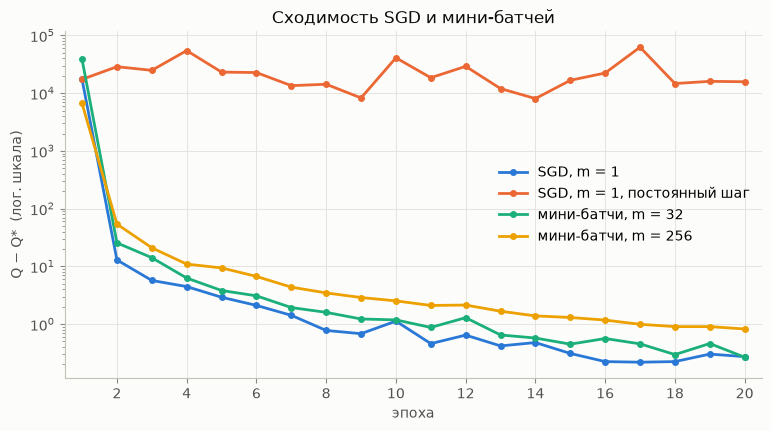

In [56]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sgd_runs = ['SGD, m = 1', 'SGD, m = 1, постоянный шаг', 'мини-батчи, m = 32', 'мини-батчи, m = 256']
for color, name in zip(COLORS, sgd_runs):
    excess = np.array(solvers[name].loss_history_) - q_star
    epochs = np.arange(1, len(excess) + 1)
    ax.plot(epochs, excess, marker='o', markersize=4, color=color, label=name)
ax.set(yscale='log', title='Сходимость SGD и мини-батчей', xlabel='эпоха', ylabel='Q − Q*  (лог. шкала)', xlim=(0.5, 20.5))
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.legend(loc='center right')
plt.show()

**Ответ:** все способы приходят к одному решению (RMSE на test 1039.98-1040.00), кроме SGD с постоянным шагом. Различаются они ценой и точностью:
- **Аналитическое решение и полный градиентный спуск** для этих данных самые быстрые и точные - тысячные доли секунды. Признаков всего 22, поэтому $X^\top X$ - матрица 22 × 22, и решить систему дешевле, чем хотя бы раз пройти по данным. Ускоренному спуску хватило 360 итераций.
- **Мини-батчи** векторизуют вычисления: при m = 32 точность та же, что у SGD по одному объекту ($Q - Q^{*} \approx 0.27$ при $Q^{*} \approx 523\,000$), но в 17 раз быстрее. При m = 256 обновлений весов меньше (2840 за 20 эпох), и до минимума остаётся чуть больше: $Q - Q^{*} = 0.8$.
- **SGD по одному объекту** самый медленный: 725 тысяч шагов в цикле Python. Он нужен, когда данные не помещаются в память или приходят потоком, - там, где аналитическое решение и полный спуск недоступны.
- **Без затухания шага и усреднения** SGD застревает на уровне шума: $Q - Q^{*} \approx 16\,000$ (3 % от $Q^{*}$), и RMSE на test хуже на 14 $. На графике его линия не опускается вообще.